# **Epidemic Question Answering with Biomedical RAG: Delivering Trusted Answers During Public Health Crises**


# **Part 1 - Business Problem**

**Business Problem**

> **Context**
> During a public health crisis, such as the COVID-19 pandemic, health authorities, hospitals, and the general public face an overwhelming volume of scientific literature and misinformation. Thousands of new articles are published every week, and both experts and citizens struggle to find reliable, up-to-date answers to urgent questions about transmission, symptoms, treatment, prevention, and vaccines.
>
> **Problem**
> Manual search through scientific papers is slow, requires domain expertise, and does not scale. Generic search engines return noisy results and cannot guarantee that an answer is grounded in trusted sources. Delays in finding accurate information can lead to poor clinical decisions, ineffective public communication, and the spread of misinformation.
>
> **Objective**
> Build an automated question answering system that, given a question about an epidemic, retrieves the most relevant scientific documents and produces a clear, evidence-based answer. The solution combines a biomedical retriever and reranker with a large language model (Retrieval-Augmented Generation, RAG), so every answer is traceable to its source.
>
> **Success Metrics**
> - Retrieval quality: Recall@k and MRR against the annotated relevant documents
> - Answer quality: relevance and faithfulness to the source text, compared with the annotated expert and consumer answers
> - Latency per question, to confirm the system is usable in near real time
>
> **Business Impact**
> Faster access to trustworthy information for health professionals, shorter research time for analysts, and a reduction in the risk of misinformation reaching the public. The same architecture can be reused for future outbreaks or other medical knowledge bases.

# Part 2 - API

In [30]:
!pip install ipykernel python-dotenv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 65.2 MB/s eta 0:00:0000:0100:01


In [31]:
import os
import math
import gc
import time
import json
import random
import subprocess
import xml.etree.ElementTree as ET
from collections import Counter
from tqdm.auto import tqdm
from google.colab import drive

import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

import torch
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import (DataCollatorWithPadding, Trainer, TrainingArguments)

from sklearn.model_selection import GroupShuffleSplit
from sklearn.model_selection import train_test_split

from sklearn.metrics import average_precision_score, roc_auc_score, f1_score, accuracy_score
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import (ConfusionMatrixDisplay, confusion_matrix, classification_report, precision_recall_curve,)

from google.colab import userdata
from huggingface_hub import login, whoami

In [2]:
import nltk
from nltk.tokenize import sent_tokenize

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

True

In [3]:
# mount Drive only if it is not mounted yet / montar o Drive só se ainda não estiver montado
if not os.path.isdir(r"/content/drive/MyDrive"):
    drive.mount("/content/drive")

# paths / caminhos
bio_dir = r"/content/biorxiv"
shard_dir = r"/content/biorxiv_shards_v2"
work_dir = r"/content/drive/MyDrive/biorxiv_classifier"
paths_file = r"/content/xml_paths.txt"
script_path = r"/content/parse_shard_v2.py"
full_path = os.path.join(work_dir, "articles_full_v2.parquet")
os.makedirs(shard_dir, exist_ok=True)
os.makedirs(work_dir, exist_ok=True)

Mounted at /content/drive


In [6]:
"""EPIC-QA - Kaggle authentication and dataset download.

Autentica no Kaggle via Secrets do Colab e baixa o dataset EPIC-QA.
"""

# load token from Colab Secrets / carregar o token dos Secrets do Colab
#os.environ["KAGGLE_API_TOKEN"] = userdata.get("kaggle_api")

# check free disk space / checar espaço livre em disco
#!df -h /content | tail -n 1

'EPIC-QA - Kaggle authentication and dataset download.\n\nAutentica no Kaggle via Secrets do Colab e baixa o dataset EPIC-QA.\n'

In [32]:
"""Epidemic-Question-Transformer-RoBERTa - kernel location check.

Mostra o sistema operacional, a pasta de trabalho e se o kernel é o Colab, sem imprimir segredos.
"""

import os
import platform
import sys

# operating system and python of the running kernel / sistema operacional e python do kernel em execução
print("system:", platform.system(), platform.release())
print("python:", sys.version.split()[0], "|", sys.executable)

# current working directory of the kernel / pasta de trabalho atual do kernel
print("working directory:", os.getcwd())

# the colab runtime exposes this module / o runtime do Colab expõe este módulo
print("running on colab:", "google.colab" in sys.modules or os.path.isdir(r"/content"))

system: Linux 6.6.122+
python: 3.13.15 | /usr/bin/python3
working directory: /content
running on colab: True


In [11]:
# download and unzip the dataset (about 10 GB) / baixar e descompactar o dataset (cerca de 10 GB)
bio_dir = r"/content/biorxiv"
os.makedirs(bio_dir, exist_ok=True)
!kaggle datasets download -d abuzarmahmood/bioarxiv-xml-100k -p {bio_dir} --unzip

Dataset URL: https://www.kaggle.com/datasets/abuzarmahmood/bioarxiv-xml-100k
License(s): other
100% 2.28G/2.28G [00:06<00:00, 375MB/s]



In [18]:
# confirm download: size per folder / confirmar download: tamanho por pasta
!du -sh {dataset_dir}/*

du: cannot access '{dataset_dir}/*': No such file or directory


In [63]:
# load token from Colab Secrets / carregar o token dos Secrets do Colab
#hf_token = userdata.get("HF_TOKEN")
#os.environ["HF_TOKEN"] = hf_token

# log in to Hugging Face Hub / fazer login no Hugging Face Hub
#login(token=hf_token)

In [36]:
# download only if the folder is empty / baixar apenas se a pasta estiver vazia
if not os.listdir(bio_dir):
    !kaggle datasets download -d abuzarmahmood/bioarxiv-xml-100k -p {bio_dir} --unzip

# list every xml file and save the list / listar todos os xml e salvar a lista
xml_paths = []
for root_dir, dirs, files in os.walk(bio_dir):
    for file_name in files:
        if file_name.lower().endswith(".xml"):
            xml_paths.append(os.path.join(root_dir, file_name))
xml_paths.sort()
with open(paths_file, "w", encoding="utf-8") as f:
    f.write("\n".join(xml_paths))

print("xml files:", len(xml_paths))
print("cpu cores:", os.cpu_count())

xml files: 99875
cpu cores: 48


# **Part 3 - GPU**

In [23]:
# GPU summary: model, driver, CUDA and memory / resumo da GPU: modelo, driver, CUDA e memória
!nvidia-smi

Sat Oct 10 21:36:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX PRO 6000 Blac...    Off |   00000000:05:00.0 Off |                    0 |
| N/A   27C    P0             46W /  600W |       0MiB /  97887MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [24]:
# check the GPU / checar a GPU
import torch

print(torch.cuda.get_device_name(0))

NVIDIA RTX PRO 6000 Blackwell Server Edition


# **Part 4 - Database**

In [37]:
# paths / caminhos
bio_dir = r"/content/biorxiv"
work_dir = r"/content/drive/MyDrive/biorxiv_classifier"

In [38]:
os.makedirs(bio_dir, exist_ok=True)
os.makedirs(work_dir, exist_ok=True)
articles_path = os.path.join(work_dir, "articles.parquet")

In [39]:
# labels that describe the result type, not the research area / rótulos que descrevem o tipo de resultado, não a área
random_seed = 42
ignored_subjects = {"new results", "confirmatory results", "contradictory results"}

random.seed(random_seed)
np.random.seed(random_seed)
print(torch.cuda.get_device_name(0))

NVIDIA RTX PRO 6000 Blackwell Server Edition


# **Part 5 - Preprocessing**

In [40]:
# list every xml file and save the list / listar todos os xml e salvar a lista
xml_paths = []
for root_dir, dirs, files in os.walk(bio_dir):
    for file_name in files:
        if file_name.lower().endswith(".xml"):
            xml_paths.append(os.path.join(root_dir, file_name))
xml_paths.sort()
with open(paths_file, "w", encoding="utf-8") as f:
    f.write("\n".join(xml_paths))
print("xml files:", len(xml_paths))

xml files: 99875


In [41]:
# script run by each process on its slice of files / script executado por cada processo na sua fatia de arquivos
parse_script = '''"""Parse one shard of bioRxiv XML files into a Parquet file."""

import os
import sys
import pandas as pd
import xml.etree.ElementTree as ET

shard_id = int(sys.argv[1])
n_shards = int(sys.argv[2])
paths_file = sys.argv[3]
out_dir = sys.argv[4]

with open(paths_file, "r", encoding="utf-8") as f:
    all_paths = [line.strip() for line in f if line.strip()]

rows = []
n_failed = 0
for xml_path in all_paths[shard_id::n_shards]:
    # parse and skip unreadable files / ler e pular arquivos ilegíveis
    try:
        root = ET.parse(xml_path).getroot()
    except Exception:
        n_failed += 1
        continue

    title = ""
    abstract = ""
    doi = ""
    subject = ""
    for element in root.iter():
        if not isinstance(element.tag, str):
            continue
        tag = element.tag.split("}")[-1]
        if tag == "article-title" and not title:
            title = " ".join("".join(element.itertext()).split())
        elif tag == "abstract" and not abstract:
            abstract = " ".join("".join(element.itertext()).split())
        elif tag == "article-id" and not doi and element.attrib.get("pub-id-type") == "doi":
            doi = (element.text or "").strip()
        elif tag == "subj-group" and not subject and element.attrib.get("subj-group-type") == "hwp-journal-coll":
            # research area lives only in this subj-group type / a área de pesquisa fica só neste tipo de subj-group
            for child in element.iter():
                if isinstance(child.tag, str) and child.tag.split("}")[-1] == "subject":
                    subject = (child.text or "").strip()
                    break

    rows.append(
        {
            "article_id": os.path.splitext(os.path.basename(xml_path))[0],
            "title": title,
            "abstract": abstract,
            "subject": subject,
            "doi": doi,
        }
    )

pd.DataFrame(rows).to_parquet(os.path.join(out_dir, f"shard_{shard_id}.parquet"), index=False)
with open(os.path.join(out_dir, f"shard_{shard_id}.failed"), "w") as f:
    f.write(str(n_failed))
'''
with open(script_path, "w", encoding="utf-8") as f:
    f.write(parse_script)

if os.path.exists(full_path):
    articles_full = pd.read_parquet(full_path)
    print("loaded cached articles:", articles_full.shape)
else:
    n_shards = os.cpu_count()
    start_time = time.time()

    # clean old shard files / limpar arquivos de partes antigas
    for old_file in os.listdir(shard_dir):
        os.remove(os.path.join(shard_dir, old_file))

    # launch one process per shard / lançar um processo por parte
    processes = [
        subprocess.Popen(["python", script_path, str(shard_id), str(n_shards), paths_file, shard_dir])
        for shard_id in range(n_shards)
    ]

    # wait and report progress / aguardar e mostrar o progresso
    while any(process.poll() is None for process in processes):
        done = len([name for name in os.listdir(shard_dir) if name.endswith(".parquet")])
        print(f"shards done: {done}/{n_shards} | {time.time() - start_time:.0f}s", end="\r")
        time.sleep(5)
    print()

    # combine all shards and save to Drive / juntar todas as partes e salvar no Drive
    shard_files = sorted(name for name in os.listdir(shard_dir) if name.endswith(".parquet"))
    articles_full = pd.concat(
        [pd.read_parquet(os.path.join(shard_dir, name)) for name in shard_files], ignore_index=True
    )
    n_failed = sum(int(open(os.path.join(shard_dir, name)).read()) for name in os.listdir(shard_dir) if name.endswith(".failed"))
    print("unreadable files:", n_failed)
    articles_full.to_parquet(full_path, index=False)
    print(f"parsed in {time.time() - start_time:.0f}s")

loaded cached articles: (99868, 5)


In [42]:
# dataset overview / visão geral do dataset
articles_full["abstract_words"] = articles_full["abstract"].str.split().str.len().fillna(0)
articles_full

,article_id,title,abstract,subject,doi,abstract_words
0,405001,Noise-induced properties of active dendrites,Dendrites play an essential role in the integr...,Neuroscience,10.1101/2020.11.30.405001,193
1,376681,Extreme genetic structure and dynamic range ev...,Abstract Aim Employ phylogeographic analyses o...,Evolutionary Biology,10.1101/376681,371
2,512174,Studying metal-protein interactions using fluo...,Abstract Metals are widespread environmental t...,Biochemistry,10.1101/2022.10.13.512174,189
3,473215,MixEHR-Guided: A guided multi-modal topic mode...,Abstract Electronic Health Records (EHRs) cont...,Bioinformatics,10.1101/2021.12.17.473215,265
4,177691,Transgene-free hematopoietic stem and progenit...,Introductory paragraph The successful producti...,Cell Biology,10.1101/177691,187
...,...,...,...,...,...,...
99863,423721,The SARS-CoV-2 spike protein disrupts the coop...,Abstract Background Severe coronavirus disease...,Cell Biology,10.1101/2020.12.21.423721,492
99864,073759,Functional connectivity models for decoding of...,Abstract Hippocampus stores spatial representa...,Neuroscience,10.1101/073759,226
99865,480194,Universal architectural concepts underlying pr...,ABSTRACT What is the architectural ‘basis set’...,Bioinformatics,10.1101/480194,139
99866,170308,dropClust: Efficient clustering of ultra-large...,ABSTRACT Droplet based single cell transcripto...,Genomics,10.1101/170308,81


## Dataset Overview

**What the table shows:** 99,868 articles (rows) and 6 columns: `article_id`, `title`, `abstract`, `subject`, `doi`, and `abstract_words`, the last one created in the cell above to count the words in each abstract. Each row is one bioRxiv article, parsed from the raw XML files.

### Observations

1. **Article count.** 99,875 XML files were found and the table has 99,868 rows. The gap of 7 is probably files that could not be parsed. This still needs to be confirmed in the output of the parallel parsing step (`unreadable files`).

2. **Abstracts carry a section label at the start.** Several rows begin with "Abstract", "ABSTRACT", or "Introductory paragraph", and some with "Abstract Background" or "Abstract Aim". This label is included in the word count and adds noise to the search embeddings, so it is worth removing before building the RAG. Only 10 rows are visible, so we do not yet know how common this is.

3. **Abstract length.** In the visible rows, `abstract_words` ranges from 81 to 492. This is only a sample, and the real distribution (percentiles, very short or very long abstracts) will be measured in the length analysis. It determines the tokenizer's `max_length`, since abstracts longer than the limit get truncated at the end.

4. **The subject is not the topic.** The article "The SARS-CoV-2 spike protein disrupts the coop..." is labeled `Cell Biology`, not a virology or epidemiology area. The `subject` column is the research area chosen by the authors, not what the text is about. To filter COVID-19 articles for the RAG, we need keyword matching on title and abstract rather than the subject.

5. **Two DOI formats.** Some DOIs include a date (`10.1101/2020.11.30.405001`) and others only the number (`10.1101/376681`), but all share the bioRxiv prefix. The final number of the DOI matches the `article_id`, so the id identifies the article and can be used to build its link. This also helps with duplicate checks.

6. **Row order is meaningless.** Rows appear shuffled, not sorted by area, id, or date, because the shards parsed in parallel were concatenated. No step should depend on row position. If the dataframe is rebuilt, the saved embeddings no longer match the articles.

### What this table does not answer yet

| Question | Why it matters |
|---|---|
| How many fields are empty (abstract, subject, DOI)? | Articles without a subject are left out of classification, and without an abstract they are left out of the RAG |
| Are there duplicate articles? | Duplicates across train and test inflate the metrics |
| How are the subjects distributed? | Defines the class imbalance and which areas have enough articles |
| What is the distribution of abstract length? | Defines `max_length` and how long texts get truncated |
| How many articles mention COVID-19? | Shows the corpus size if the RAG is limited to that topic |

In [43]:
articles_full.shape

(99868, 6)

In [44]:
print("with abstract (30+ words):", int((articles_full["abstract_words"] >= 30).sum()))

with abstract (30+ words): 99540


In [45]:
print("with research area:", int((articles_full["subject"] != "").sum()))

with research area: 99843


In [46]:
articles_full["subject"].value_counts()

,count
subject,
Neuroscience,18186
Bioinformatics,10361
Microbiology,8093
Evolutionary Biology,7042
Genomics,6511
Cell Biology,4883
Genetics,4820
Ecology,4462
Biophysics,4345


# **Part 6 - Train Test split**

In [47]:
"""bioRxiv v2 - check Drive and build the splits when possible.

Verifica o que existe no Drive e cria os splits v2 automaticamente se o parquet de artigos existir.
"""

import os
import pandas as pd
from google.colab import drive
from sklearn.model_selection import train_test_split

# mount Drive only if it is not mounted yet / montar o Drive só se ainda não estiver montado
if not os.path.isdir(r"/content/drive/MyDrive"):
    drive.mount("/content/drive")

work_dir = r"/content/drive/MyDrive/biorxiv_classifier"
articles_path = os.path.join(work_dir, "articles_full_v2.parquet")
split_dir = os.path.join(work_dir, "splits_v2")

# report the state of the key files / informar o estado dos arquivos-chave
print("project folder exists:", os.path.isdir(work_dir))
if os.path.isdir(work_dir):
    print("folder contents:", sorted(os.listdir(work_dir)))
print("articles_full_v2.parquet:", os.path.exists(articles_path))
print("splits_v2/train.parquet:", os.path.exists(os.path.join(split_dir, "train.parquet")))
print("dataset in this VM:", os.path.isdir(r"/content/biorxiv") and len(os.listdir(r"/content/biorxiv")) > 0)

if os.path.exists(os.path.join(split_dir, "train.parquet")):
    print("splits already exist, nothing to do")
elif not os.path.exists(articles_path):
    print("articles_full_v2.parquet is missing: run the parallel parsing cell (v2) first")
else:
    # load articles and keep usable rows / carregar artigos e manter as linhas utilizáveis
    articles_full = pd.read_parquet(articles_path)
    articles_full["abstract_words"] = articles_full["abstract"].str.split().str.len().fillna(0)
    usable_df = articles_full[
        (articles_full["abstract_words"] >= 30)
        & (articles_full["title"].str.len() > 0)
        & (articles_full["subject"] != "")
    ].reset_index(drop=True)

    # unify spelling variants using the most common form / unificar variações de grafia pela forma mais comum
    usable_df["subject_key"] = usable_df["subject"].str.strip().str.lower()
    canonical_names = usable_df.groupby("subject_key")["subject"].agg(lambda names: names.value_counts().index[0])
    usable_df["subject"] = usable_df["subject_key"].map(canonical_names)
    usable_df = usable_df.drop(columns="subject_key")

    # keep areas with enough articles / manter áreas com artigos suficientes
    random_seed = 42
    area_counts = usable_df["subject"].value_counts()
    kept_areas = area_counts[area_counts >= 300].index.tolist()
    split_df = usable_df[usable_df["subject"].isin(kept_areas)].reset_index(drop=True)
    print("usable:", len(usable_df), "| areas kept:", len(kept_areas), "| articles:", len(split_df))

    # stratified 70/15/15 split / divisão estratificada 70/15/15
    train_val_df, test_df = train_test_split(
        split_df, test_size=0.15, stratify=split_df["subject"], random_state=random_seed
    )
    train_df, val_df = train_test_split(
        train_val_df, test_size=0.15 / 0.85, stratify=train_val_df["subject"], random_state=random_seed
    )

    # save the splits to Drive / salvar as divisões no Drive
    os.makedirs(split_dir, exist_ok=True)
    train_df.reset_index(drop=True).to_parquet(os.path.join(split_dir, "train.parquet"), index=False)
    val_df.reset_index(drop=True).to_parquet(os.path.join(split_dir, "val.parquet"), index=False)
    test_df.reset_index(drop=True).to_parquet(os.path.join(split_dir, "test.parquet"), index=False)
    print("train:", len(train_df), "| val:", len(val_df), "| test:", len(test_df))
    print("splits saved to", split_dir)

project folder exists: True
folder contents: ['articles_full_v2.parquet', 'rag', 'roberta_classifier_v2', 'splits_v2']
articles_full_v2.parquet: True
splits_v2/train.parquet: True
dataset in this VM: True
splits already exist, nothing to do


## Subject Distribution

**What the table shows:** how many articles each `subject` value has across the full dataset of 99,868 articles. The 44 raw values are not 44 research areas: 27 are real areas, and the rest are blank labels and spelling variants of those areas (observations 1 and 2).

### Observations

1. **25 articles have no subject.** The unnamed row with a count of 25 is the empty label. The counts add up to exactly 99,868 only if it is included. These articles cannot be used for classification, but they can still be used in the RAG, which does not depend on the subject.

2. **Some labels are duplicates written differently.** 13 labels are uppercase copies of real areas (`BIOINFORMATICS` 14, `GENOMICS` 12, `EVOLUTIONARY BIOLOGY` 11, `NEUROSCIENCE` 8 and so on), adding up to 70 articles. There are also three stray labels: `Scientific Communication and Education` (10), `Clinical_Trials` (2) and `Psychiatry and Clinical Psychology` (1). These would be counted as separate classes if left alone. The split already lowercases labels, which merges the uppercase variants. The three stray labels are not merged and fall under the minimum size.

3. **The classes are very imbalanced.** Neuroscience alone holds 18.2% of the articles and Bioinformatics 10.4%. The top 5 areas hold 50.3% of the dataset. At the other end, Clinical Trials has 86 articles, about 210 times fewer than Neuroscience. Seven areas have fewer than 1,000 articles. This is why accuracy is a misleading metric here: always predicting Neuroscience already scores about 18%, so macro F1 and per-area results matter more.

4. **25 areas had enough articles to be used.** With a minimum of 300 articles per area, 25 areas remain. Paleontology (132) and Clinical Trials (86) are left out, together with the stray labels, at least 231 labeled articles in total. Dropping them is a deliberate choice: with so few articles, a stratified split would leave only a handful in validation and test, and any metric for them would be noise.

5. **The training cap changes the training distribution.** Training uses at most 4,000 articles per area. Assuming a 70% training share, five areas exceed that (Neuroscience, Bioinformatics, Microbiology, Evolutionary Biology and Genomics), so they are undersampled. Validation and test keep the real distribution. The model therefore trains on a more balanced mix than the one it is evaluated on, which can lower precision in small areas. This is a hypothesis to check against the per-area report.

6. **The labels overlap in meaning.** Genomics, Genetics and Bioinformatics are neighbors, as are Molecular Biology, Biochemistry and Cell Biology. Each article has a single area chosen by its authors, so some of the confusion between these areas comes from the labels and not from the model.

### Decisions taken from this table

| Decision | Reason |
|---|---|
| Merge uppercase variants by lowercasing | They are the same area written differently |
| Drop areas with fewer than 300 articles | Too few articles for a reliable split and evaluation |
| Keep blank-subject articles out of classification only | They are still valid documents for the RAG |
| Report macro F1 and per-area results, not only accuracy | The majority class alone reaches about 18% |

In [48]:
# split settings / parâmetros da divisão
random_seed = 42
min_articles_per_area = 300
val_size = 0.15
test_size = 0.15

split_dir = os.path.join(work_dir, "splits_v2")
os.makedirs(split_dir, exist_ok=True)

import os
import pandas as pd
from sklearn.model_selection import train_test_split

# stop with a clear message if the parsing cell was not run / parar com mensagem clara se a célula de leitura não foi executada
work_dir = r"/content/drive/MyDrive/biorxiv_classifier"
if "articles_full" not in globals():
    articles_full = pd.read_parquet(os.path.join(work_dir, "articles_full_v2.parquet"))
articles_full["abstract_words"] = articles_full["abstract"].str.split().str.len().fillna(0)

split_dir = os.path.join(work_dir, "splits_v2")
os.makedirs(split_dir, exist_ok=True)

In [49]:
# keep articles with enough abstract text, a title and a research area / manter artigos com resumo suficiente, título e área
usable_df = articles_full[
    (articles_full["abstract_words"] >= 30)
    & (articles_full["title"].str.len() > 0)
    & (articles_full["subject"] != "")
].reset_index(drop=True)

# unify spelling variants using the most common form of each area / unificar variações de grafia usando a forma mais comum de cada área
usable_df["subject_key"] = usable_df["subject"].str.strip().str.lower()
canonical_names = usable_df.groupby("subject_key")["subject"].agg(lambda names: names.value_counts().index[0])
usable_df["subject"] = usable_df["subject_key"].map(canonical_names)
usable_df = usable_df.drop(columns="subject_key")
print("usable articles:", len(usable_df), "of", len(articles_full))

usable articles: 99515 of 99868


In [50]:
# split settings / parâmetros da divisão
random_seed = 42
min_articles_per_area = 300
val_size = 0.15
test_size = 0.15

# keep only areas with enough articles / manter só áreas com artigos suficientes
area_counts = usable_df["subject"].value_counts()
kept_areas = area_counts[area_counts >= min_articles_per_area].index.tolist()
split_df = usable_df[usable_df["subject"].isin(kept_areas)].reset_index(drop=True)
print("areas kept:", len(kept_areas), "of", len(area_counts), "|", len(split_df), "articles")


areas kept: 25 of 30 | 99286 articles


In [55]:
# confirm that no article appears in two sets / confirmar que nenhum artigo aparece em dois conjuntos
train_ids = set(train_df["article_id"])
print("overlap train/val:", len(train_ids & set(val_df["article_id"])), "| train/test:", len(train_ids & set(test_df["article_id"])))


overlap train/val: 4367 | train/test: 4494


In [56]:
# class distribution per split / distribuição das classes por conjunto
print(pd.DataFrame(
    {
        "train": train_df["subject"].value_counts(),
        "val": val_df["subject"].value_counts(),
        "test": test_df["subject"].value_counts(),
    }
))

# save the splits to Drive / salvar as divisões no Drive
train_df.to_parquet(os.path.join(split_dir, "train.parquet"), index=False)
val_df.to_parquet(os.path.join(split_dir, "val.parquet"), index=False)
test_df.to_parquet(os.path.join(split_dir, "test.parquet"), index=False)
print("splits saved to", split_dir)

                               train   val  test
subject                                         
Animal Behavior and Cognition   1155   248   248
Biochemistry                    2181   467   467
Bioengineering                  1528   327   327
Bioinformatics                  4000  1550  1550
Biophysics                      3030   649   649
Cancer Biology                  2358   505   505
Cell Biology                    3409   731   731
Developmental Biology           2035   436   436
Ecology                         3110   667   666
Epidemiology                     871   187   187
Evolutionary Biology            4000  1055  1056
Genetics                        3360   720   720
Genomics                        4000   974   974
Immunology                      2091   448   448
Microbiology                    4000  1212  1212
Molecular Biology               2185   468   468
Neuroscience                    4000  2723  2722
Pathology                        348    74    75
Pharmacology        

# Part 7 - Model LLM

In [53]:
# settings: v2 folders so old checkpoints are never reused / parâmetros: pastas v2 para nunca reaproveitar checkpoints antigos
work_dir = r"/content/drive/MyDrive/biorxiv_classifier"
split_dir = os.path.join(work_dir, "splits_v2")
output_dir = os.path.join(work_dir, "roberta_classifier_v2")
os.makedirs(output_dir, exist_ok=True)
model_name = "deepset/roberta-large-squad2"
max_length = 384
max_train_per_class = 4000
random_seed = 42

In [54]:
# load the v2 splits / carregar os splits v2
train_df = pd.read_parquet(os.path.join(split_dir, "train.parquet"))
val_df = pd.read_parquet(os.path.join(split_dir, "val.parquet"))
test_df = pd.read_parquet(os.path.join(split_dir, "test.parquet"))

# cap the largest areas in training only / limitar as maiores áreas só no treino
train_df = train_df.sample(frac=1.0, random_state=random_seed).reset_index(drop=True)
train_df = train_df[train_df.groupby("subject").cumcount() < max_train_per_class].reset_index(drop=True)

# label mappings and numeric labels / mapeamentos de rótulos e rótulos numéricos
label_names = sorted(train_df["subject"].unique())
label2id = {name: idx for idx, name in enumerate(label_names)}
id2label = {idx: name for name, idx in label2id.items()}
for split_frame in (train_df, val_df, test_df):
    split_frame["label"] = split_frame["subject"].map(label2id)
print(len(label_names), "areas | train:", len(train_df), "| val:", len(val_df), "| test:", len(test_df))
print(train_df["subject"].value_counts())

# tokenize title and abstract as a text pair / tokenizar título e resumo como par de textos
tokenizer = AutoTokenizer.from_pretrained(model_name)
datasets_by_split = {}
for split_name, split_frame in [("train", train_df), ("val", val_df), ("test", test_df)]:
    split_ds = Dataset.from_pandas(split_frame[["title", "abstract", "label"]], preserve_index=False)
    split_ds = split_ds.map(
        lambda batch: tokenizer(
            batch["title"], batch["abstract"], truncation="only_second", max_length=max_length
        ),
        batched=True,
        remove_columns=["title", "abstract"],
    ).rename_column("label", "labels")
    datasets_by_split[split_name] = split_ds

# sanity checks that prevent device-side asserts / checagens que evitam erros de assert no dispositivo
print("max token id:", max(max(ids) for ids in datasets_by_split["train"]["input_ids"]), "| vocab size:", len(tokenizer))
print("labels from", min(datasets_by_split["train"]["labels"]), "to", max(datasets_by_split["train"]["labels"]), "| classes:", len(label_names))
print("nulls in labels:", int(train_df["label"].isna().sum() + val_df["label"].isna().sum() + test_df["label"].isna().sum()))

gc.collect()
torch.cuda.empty_cache()

25 areas | train: 54437 | val: 14893 | test: 14893
subject
Neuroscience                     4000
Microbiology                     4000
Bioinformatics                   4000
Genomics                         4000
Evolutionary Biology             4000
Cell Biology                     3409
Genetics                         3360
Ecology                          3110
Biophysics                       3030
Cancer Biology                   2358
Molecular Biology                2185
Biochemistry                     2181
Immunology                       2091
Developmental Biology            2035
Plant Biology                    2031
Systems Biology                  1855
Bioengineering                   1528
Animal Behavior and Cognition    1155
Epidemiology                      871
Physiology                        868
Synthetic Biology                 642
Pharmacology                      604
Scientific Communication          435
Pathology                         348
Zoology                      

config.json:   0%|          | 0.00/696 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.19k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Map:   0%|          | 0/54437 [00:00<?, ? examples/s]

Map:   0%|          | 0/14893 [00:00<?, ? examples/s]

Map:   0%|          | 0/14893 [00:00<?, ? examples/s]

max token id: 50155 | vocab size: 50265
labels from 0 to 24 | classes: 25
nulls in labels: 0


In [57]:
# load the v2 splits / carregar os splits v2
train_df = pd.read_parquet(os.path.join(split_dir, "train.parquet"))
val_df = pd.read_parquet(os.path.join(split_dir, "val.parquet"))
test_df = pd.read_parquet(os.path.join(split_dir, "test.parquet"))

# cap the largest areas in training only / limitar as maiores áreas só no treino
train_df = train_df.sample(frac=1.0, random_state=random_seed).reset_index(drop=True)
train_df = train_df[train_df.groupby("subject").cumcount() < max_train_per_class].reset_index(drop=True)

# label mappings and numeric labels / mapeamentos de rótulos e rótulos numéricos
label_names = sorted(train_df["subject"].unique())
label2id = {name: idx for idx, name in enumerate(label_names)}
id2label = {idx: name for name, idx in label2id.items()}
for split_frame in (train_df, val_df, test_df):
    split_frame["label"] = split_frame["subject"].map(label2id)
print(len(label_names), "areas | train:", len(train_df), "| val:", len(val_df), "| test:", len(test_df))
print(train_df["subject"].value_counts())

25 areas | train: 54437 | val: 14893 | test: 14893
subject
Genomics                         4000
Neuroscience                     4000
Bioinformatics                   4000
Evolutionary Biology             4000
Microbiology                     4000
Cell Biology                     3409
Genetics                         3360
Ecology                          3110
Biophysics                       3030
Cancer Biology                   2358
Molecular Biology                2185
Biochemistry                     2181
Immunology                       2091
Developmental Biology            2035
Plant Biology                    2031
Systems Biology                  1855
Bioengineering                   1528
Animal Behavior and Cognition    1155
Epidemiology                      871
Physiology                        868
Synthetic Biology                 642
Pharmacology                      604
Scientific Communication          435
Pathology                         348
Zoology                      

# **Part 8 - Model Embedding**

In [58]:
"""bioRxiv RoBERTa classification - tokenization.

Tokeniza título e resumo como um par de textos e valida ids de token e rótulos.
"""

from datasets import Dataset
from transformers import AutoTokenizer

# load the tokenizer of the base model / carregar o tokenizer do modelo base
tokenizer = AutoTokenizer.from_pretrained(model_name)

In [59]:
# tokenize title and abstract as a text pair / tokenizar título e resumo como par de textos
tokenizer = AutoTokenizer.from_pretrained(model_name)
datasets_by_split = {}
for split_name, split_frame in [("train", train_df), ("val", val_df), ("test", test_df)]:
    split_ds = Dataset.from_pandas(split_frame[["title", "abstract", "label"]], preserve_index=False)
    split_ds = split_ds.map(
        lambda batch: tokenizer(
            batch["title"], batch["abstract"], truncation="only_second", max_length=max_length
        ),
        batched=True,
        remove_columns=["title", "abstract"],
    ).rename_column("label", "labels")
    datasets_by_split[split_name] = split_ds

# sanity checks that prevent device-side asserts / checagens que evitam erros de assert no dispositivo
print("max token id:", max(max(ids) for ids in datasets_by_split["train"]["input_ids"]), "| vocab size:", len(tokenizer))
print("labels from", min(datasets_by_split["train"]["labels"]), "to", max(datasets_by_split["train"]["labels"]), "| classes:", len(label_names))
print("nulls in labels:", int(train_df["label"].isna().sum() + val_df["label"].isna().sum() + test_df["label"].isna().sum()))

gc.collect()
torch.cuda.empty_cache()

Map:   0%|          | 0/54437 [00:00<?, ? examples/s]

Map:   0%|          | 0/14893 [00:00<?, ? examples/s]

Map:   0%|          | 0/14893 [00:00<?, ? examples/s]

max token id: 50155 | vocab size: 50265
labels from 0 to 24 | classes: 25
nulls in labels: 0


# **Part 9 - Train model**

In [60]:
# load the encoder with a new classification head / carregar o encoder com uma cabeça de classificação nova
model = AutoModelForSequenceClassification.from_pretrained(model_name,
                                                           num_labels=len(label_names),
                                                           id2label=id2label,
                                                           label2id=label2id,
                                                           )

# metrics computed at each evaluation / métricas calculadas a cada avaliação
compute_metrics = lambda eval_pred: {"accuracy": accuracy_score(eval_pred.label_ids, eval_pred.predictions.argmax(axis=-1)),
                                     "f1_macro": f1_score(eval_pred.label_ids, eval_pred.predictions.argmax(axis=-1), average="macro"),
                                     }

# warmup of 10% of the total steps / aquecimento de 10% do total de passos
num_epochs = 3
batch_size = 32
total_steps = math.ceil(len(train_df) / batch_size) * num_epochs

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: deepset/roberta-large-squad2
Key                        | Status     | 
---------------------------+------------+-
qa_outputs.bias            | UNEXPECTED | 
qa_outputs.weight          | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [61]:
training_args = TrainingArguments(output_dir=os.path.join(output_dir, "checkpoints"),
                                  num_train_epochs=num_epochs,
                                  per_device_train_batch_size=batch_size,
                                  per_device_eval_batch_size=128,
                                  learning_rate=1e-5,
                                  weight_decay=0.01, warmup_steps=int(0.1 * total_steps),
                                  bf16=True,
                                  eval_strategy="epoch",
                                  save_strategy="epoch",
                                  save_total_limit=1,
                                  load_best_model_at_end=True,
                                  metric_for_best_model="f1_macro",
                                  logging_steps=50,
                                  report_to="none",
                                  seed=random_seed,
                                  )

trainer = Trainer(model=model,
                  args=training_args,
                  train_dataset=datasets_by_split["train"],
                  eval_dataset=datasets_by_split["val"],
                  data_collator=DataCollatorWithPadding(tokenizer),
                  processing_class=tokenizer,
                  compute_metrics=compute_metrics,
                  )

# resume from the last checkpoint if one exists / retomar do último checkpoint se existir
checkpoint_dir = os.path.join(output_dir, "checkpoints")
has_checkpoint = os.path.isdir(checkpoint_dir) and any(name.startswith("checkpoint-") for name in os.listdir(checkpoint_dir))
print("resuming from checkpoint:", has_checkpoint)
trainer.train(resume_from_checkpoint=True if has_checkpoint else None)

# save the best model and tokenizer / salvar o melhor modelo e o tokenizer
best_dir = os.path.join(output_dir, "best")
trainer.save_model(best_dir)
tokenizer.save_pretrained(best_dir)

resuming from checkpoint: True


Epoch,Training Loss,Validation Loss


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/content/drive/MyDrive/biorxiv_classifier/roberta_classifier_v2/best/tokenizer_config.json',
 '/content/drive/MyDrive/biorxiv_classifier/roberta_classifier_v2/best/tokenizer.json')

In [65]:
"""EPIC-QA - training and validation loss curves.

Extrai o histórico do Trainer e plota as curvas de loss de treino e validação.
"""

# read the log history stored by the Trainer / ler o histórico de logs guardado pelo Trainer
log_df = pd.DataFrame(trainer.state.log_history)

# separate training logs and evaluation logs / separar logs de treino e logs de avaliação
train_log = log_df[log_df["loss"].notna()][["step", "epoch", "loss"]]
eval_log = log_df[log_df["eval_loss"].notna()][["step", "epoch", "eval_loss"]]

print(train_log.tail())
print(eval_log)

     step     epoch      loss
99   4900  2.878966  0.784451
100  4950  2.908343  0.760231
101  5000  2.937720  0.770703
102  5050  2.967098  0.841373
103  5100  2.996475  0.801354
     step  epoch  eval_loss
34   1702    1.0   1.019987
69   3404    2.0   0.919407
104  5106    3.0   0.916726


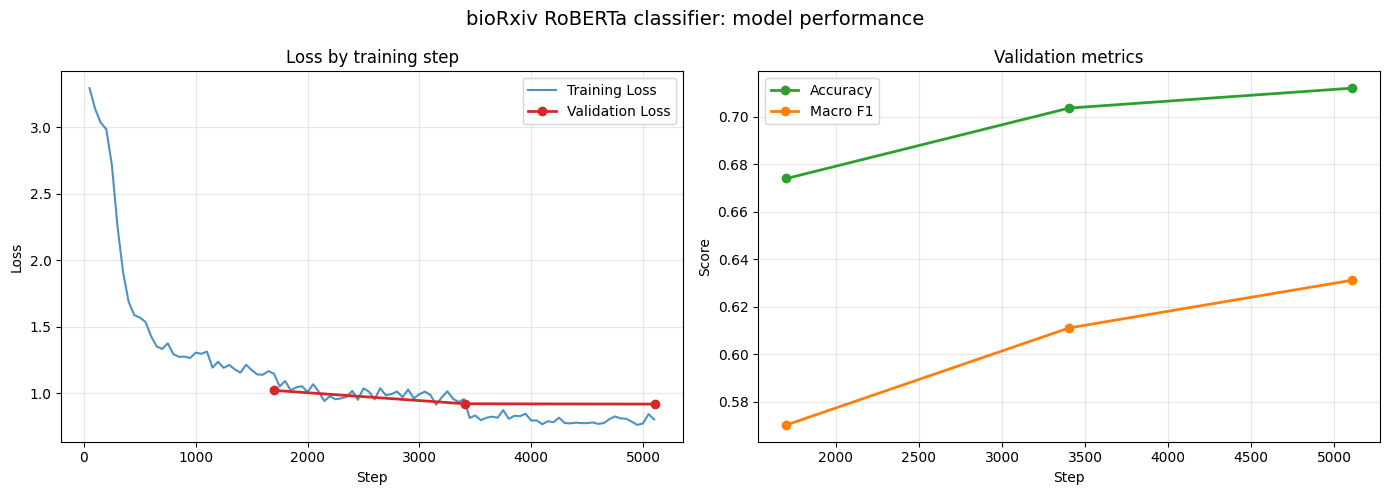

In [64]:
"""bioRxiv v2 - training and validation curves.

Plota loss de treino e validação, e acurácia e F1 macro de validação.
"""

log_df = pd.DataFrame(trainer.state.log_history)
train_log = log_df[log_df["loss"].notna()][["step", "loss"]]
eval_log = log_df[log_df["eval_loss"].notna()][["step", "eval_loss", "eval_accuracy", "eval_f1_macro"]]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# left panel: training and validation loss / painel esquerdo: loss de treino e validação
axes[0].plot(train_log["step"], train_log["loss"], label="Training Loss", color="tab:blue", alpha=0.8)
axes[0].plot(eval_log["step"], eval_log["eval_loss"], label="Validation Loss", color="tab:red", marker="o", linewidth=2)
axes[0].set_xlabel("Step")
axes[0].set_ylabel("Loss")
axes[0].set_title("Loss by training step")
axes[0].legend()
axes[0].grid(alpha=0.3)

# right panel: validation accuracy and macro F1 / painel direito: acurácia e F1 macro de validação
axes[1].plot(eval_log["step"], eval_log["eval_accuracy"], label="Accuracy", color="tab:green", marker="o", linewidth=2)
axes[1].plot(eval_log["step"], eval_log["eval_f1_macro"], label="Macro F1", color="tab:orange", marker="o", linewidth=2)
axes[1].set_xlabel("Step")
axes[1].set_ylabel("Score")
axes[1].set_title("Validation metrics")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle("bioRxiv RoBERTa classifier: model performance", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "loss_curves.png"), dpi=150, bbox_inches="tight")
plt.show()

## Training and Validation Curves

**What the plot shows:** the left panel has training loss at every logging step (blue) and validation loss at the end of each epoch (red). The right panel has validation accuracy and macro F1 at the same three evaluation points. Training ran for 3 epochs and 5,100 steps, so each epoch took about 1,700 steps.

### Observations

1. **The model started at chance level and learned quickly.** The first training loss is about 3.3, which is close to ln(25) ≈ 3.22, the loss of a model that guesses uniformly among the 25 areas. It then falls to about 1.6 within the first 400 steps, the fastest drop of the whole run. This confirms that the labels carry signal and that the training pipeline works.

2. **Validation loss improved in epoch 2 and then went flat.** It goes from about 1.02 (epoch 1) to about 0.92 (epoch 2) and stays near 0.92 in epoch 3. A loss of 0.92 means the model gives the correct area a geometric mean probability of about 0.40, against 0.04 for a random guess. Epoch 3 did not lower validation loss, so the model is close to a plateau on this measure.

3. **Accuracy and macro F1 kept rising, but with diminishing returns.** Accuracy goes from about 0.674 to 0.704 to 0.712, and macro F1 from about 0.570 to 0.611 to 0.631. Accuracy gained less than one point in the last epoch, and macro F1 gained about two points. Macro F1 improves more because small areas are still being learned, while the large areas, which dominate accuracy, are already near their ceiling.

4. **A gap between training and validation loss is opening.** Training loss ends at about 0.8 (it oscillates between roughly 0.75 and 0.85), while validation loss stays at about 0.92. There are also visible step-downs in training loss right after the epoch boundaries, larger after the second one. This pattern is typical of a model starting to memorize examples it has already seen. At this size the gap is mild, and validation metrics did not get worse.

5. **Validation loss was lower than training loss in the first epoch.** At the first evaluation point, validation loss (about 1.02) is below the average training loss around it (about 1.1). This is normal: the training loss is averaged over the whole epoch while the model is still improving and dropout is active, whereas validation is measured once, at the end, with dropout off.

6. **The two losses are not directly comparable.** Training uses at most 4,000 articles per area, a more balanced mix, while validation keeps the real distribution, dominated by easier areas such as Neuroscience. The size of the gap between the curves therefore reflects both overfitting and the difference between the two class mixes. It cannot be read as pure overfitting.

7. **Validation and test results agree.** The final validation point (accuracy about 0.712, macro F1 about 0.631) is within one point of the test result reported earlier (accuracy 0.703, macro F1 0.624). Selecting the best checkpoint on validation did not noticeably overfit it.

### Limits of this plot

| Limit | Consequence |
|---|---|
| Validation was measured only 3 times | The red curve and the right panel show a trend, not a smooth path, and the best step is known only to the nearest epoch |
| Single run, single seed | A difference of one or two points between runs can be noise, so comparing models needs more than one run |
| No second model to compare | The plot does not show whether RoBERTa-large helped or hurt compared with a biomedical model |

### Decisions taken from this plot

| Decision | Reason |
|---|---|
| Keep 3 epochs and do not train longer | Validation loss is flat and the train/validation gap is growing |
| Keep the last checkpoint | It has the best macro F1, which is the selection metric |
| Look at per-area errors instead of more epochs | Remaining errors come mostly from small and overlapping areas, which more training does not fix |
| Compare against a biomedical encoder in a later run | It is the clearest way to tell whether the base model is the limit |

# **Part 10 - Metrics and evaluations**

In [66]:
"""bioRxiv v2 - test evaluation and confusion matrix.

Avalia no conjunto de teste com F1 macro, top-3 e matriz de confusão normalizada.
"""

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# predict on the held-out test set / prever no conjunto de teste separado
test_output = trainer.predict(datasets_by_split["test"])
y_true = test_output.label_ids
test_probs = torch.softmax(torch.tensor(test_output.predictions), dim=-1).numpy()
y_pred = test_probs.argmax(axis=-1)

# main multiclass metrics / principais métricas multiclasse
print("test accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("test macro f1:", round(f1_score(y_true, y_pred, average="macro"), 4))
top3 = np.argsort(test_probs, axis=-1)[:, -3:]
print("test top-3 accuracy:", round(float(np.mean([y_true[i] in top3[i] for i in range(len(y_true))])), 4))

test accuracy: 0.7029
test macro f1: 0.624
test top-3 accuracy: 0.9215


In [67]:
# baseline: always predicting the most common area / referência: sempre prever a área mais comum
majority_share = float(np.mean(y_true == np.bincount(y_true).argmax()))
print("majority-class baseline accuracy:", round(majority_share, 4))

majority-class baseline accuracy: 0.1828


In [68]:
# per-area precision, recall and f1 / precisão, recall e f1 por área
print(classification_report(y_true, y_pred, labels=list(range(len(label_names))), target_names=label_names, digits=3, zero_division=0))

                               precision    recall  f1-score   support

Animal Behavior and Cognition      0.508     0.734     0.601       248
                 Biochemistry      0.533     0.561     0.546       467
               Bioengineering      0.513     0.554     0.532       327
               Bioinformatics      0.796     0.709     0.750      1550
                   Biophysics      0.642     0.740     0.687       649
               Cancer Biology      0.728     0.802     0.763       505
                 Cell Biology      0.594     0.636     0.614       731
        Developmental Biology      0.712     0.697     0.705       436
                      Ecology      0.776     0.802     0.789       666
                 Epidemiology      0.653     0.786     0.714       187
         Evolutionary Biology      0.746     0.779     0.762      1056
                     Genetics      0.552     0.631     0.589       720
                     Genomics      0.556     0.495     0.524       974
     

## Classification Report (Test Set)

**What the report shows:** precision, recall and F1 for each of the 25 research areas on the 14,893 test articles, which the model never saw during training or checkpoint selection. `support` is the number of test articles of each area. Overall accuracy is 0.703, macro F1 is 0.624 and weighted F1 is 0.702.

### Observations

1. **The model is far above the trivial baseline.** Always predicting Neuroscience, the most common area (2,722 of 14,893), would score 18.3% accuracy. The model reaches 70.3%, about 3.8 times more, and macro F1 of 0.624 shows it is not just favoring large areas.

2. **Macro F1 is lower than weighted F1 by almost 8 points.** Weighted F1 (0.702) gives more weight to large areas, macro F1 (0.624) treats all 25 areas equally. The gap means large areas are classified better than small ones. Macro F1 is the metric to report, since it does not hide the weak areas.

3. **11 areas are good, 9 are middling and 5 are weak.** Areas with F1 of at least 0.70: Neuroscience (0.899), Scientific Communication (0.817), Ecology and Plant Biology (0.789 each), Cancer Biology (0.763), Evolutionary Biology (0.762), Bioinformatics (0.750), Microbiology (0.731), Immunology (0.730), Epidemiology (0.714) and Developmental Biology (0.705). Weak areas, with F1 below 0.50: Pathology (0.250), Molecular Biology (0.322), Zoology (0.388), Physiology (0.443) and Pharmacology (0.482).

4. **Size does not explain performance by itself.** Molecular Biology has 3,131 articles in the full dataset, more than Immunology (2,988), Plant Biology (2,910) and Developmental Biology (2,911), yet its F1 is 0.322 against 0.70 to 0.79 for those three. Epidemiology (1,255 articles) reaches 0.714, while Physiology (1,241) reaches 0.443. Scientific Communication has only 627 articles and scores 0.817. What separates them is how distinctive the vocabulary is, not how many examples exist.

5. **Molecular Biology and Pathology are mostly missed.** Molecular Biology has recall of 0.263: roughly 123 of 468 articles are found and about 345 are sent to other areas. Pathology has recall of 0.173: roughly 13 of 75 are found. Both are generic or overlapping labels, since many molecular biology articles could also be filed under Biochemistry, Cell Biology or Genetics, and pathology under Physiology or Cancer Biology. This points to the labels more than to the model, which is a hypothesis to confirm in the confusion matrix.

6. **Genomics is weak despite having a lot of data.** It has 6,511 articles, the fifth largest area, but F1 is only 0.524 and recall is 0.495. Its neighbors Genetics (0.589) and Bioinformatics (0.750) are the likely confusions. Genomics is capped in training like the larger areas, and this is the clearest case where overlapping labels, not lack of data, limit the score.

7. **Precision and recall are balanced overall, but not by area.** Macro precision is 0.628 and macro recall is 0.632. Recall is higher than precision in 15 areas and lower in 10. The largest gaps with recall above precision are Animal Behavior and Cognition (0.734 against 0.508) and Epidemiology (0.786 against 0.653). For Animal Behavior, this implies about 358 articles predicted against 248 real ones, roughly 44% too many. The model over-predicts these areas, and many of their predictions are wrong.

8. **The training cap may explain part of that over-prediction.** Training used at most 4,000 articles per area, so the five largest areas (Neuroscience, Bioinformatics, Microbiology, Evolutionary Biology and Genomics) were undersampled, while the test set keeps the real distribution. Consistent with this, Neuroscience, Bioinformatics and Genomics have precision above recall, and Microbiology is balanced. Evolutionary Biology is the exception. This is a hypothesis, since a single run cannot separate it from label overlap.

9. **Neuroscience is the most reliable area.** F1 of 0.899 with precision of 0.933 and recall of 0.867 on 2,722 articles. When the model says Neuroscience it is right 93% of the time, and it finds 87% of the real ones. About 169 other articles were wrongly labeled Neuroscience, roughly 7% of its predictions.

10. **Some per-area numbers are noisy.** Pathology (75 articles) and Zoology (73) have the smallest supports. With samples this small, the 95% interval on recall is roughly ±9 points for Pathology and ±11 for Zoology, against about ±1 for Neuroscience. A single article changes their recall by more than one point, so small differences between these areas, or between runs, should not be over-interpreted.

### Limits of this report

| Limit | Consequence |
|---|---|
| Single run and single seed | A difference of one or two points between runs can be noise |
| Hard labels, one area per article | Overlapping areas cap the achievable accuracy, and errors there are not all model errors |
| Small supports for some areas | Pathology, Zoology, Physiology and Pharmacology have unstable estimates |
| No second model | The report does not show whether RoBERTa-large helped or hurt compared with a biomedical encoder |
| Hypotheses in points 5, 6 and 8 | They still need the confusion matrix and

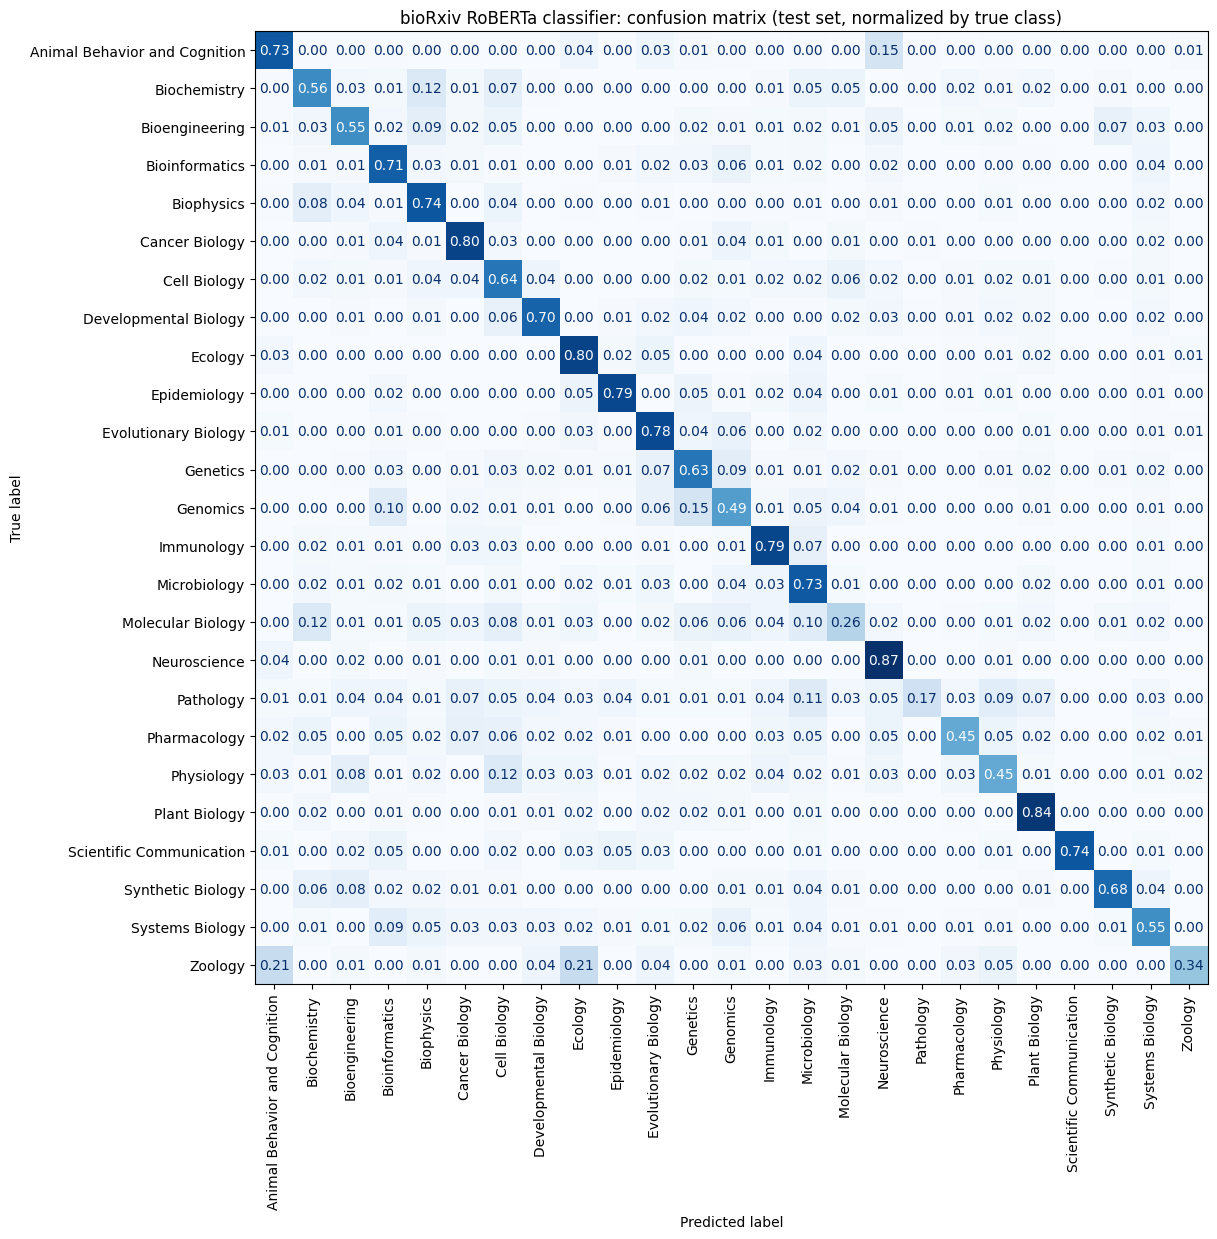

In [69]:
# normalized confusion matrix / matriz de confusão normalizada
fig, ax = plt.subplots(figsize=(max(8, len(label_names) * 0.55), max(7, len(label_names) * 0.5)))
ConfusionMatrixDisplay(
    confusion_matrix(y_true, y_pred, labels=list(range(len(label_names))), normalize="true"),
    display_labels=label_names,
).plot(ax=ax, cmap="Blues", colorbar=False, values_format=".2f", xticks_rotation=90)
ax.set_title("bioRxiv RoBERTa classifier: confusion matrix (test set, normalized by true class)")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "confusion_matrix.png"), dpi=150, bbox_inches="tight")
plt.show()

## Confusion Matrix Analysis

**What the plot shows:** the test-set confusion matrix, normalized by true class. Let $n_{ij}$ be the number of articles whose true area is $i$ and whose predicted area is $j$, $s_i=\sum_j n_{ij}$ the support of area $i$, $N=\sum_i s_i=14{,}893$ and $K=25$ areas. Each cell is

$$C_{ij}=\frac{n_{ij}}{s_i},\qquad \sum_j C_{ij}=1$$

The diagonal is recall, $C_{ii}=\mathrm{Recall}_i$, and an off-diagonal cell is the share of area $i$ that was sent to area $j$. Counts are recovered as $\hat n_{ij}=C_{ij}\,s_i$. The plot shows two decimals, so each recovered count is off by up to $\pm0.005\,s_i$ (about $\pm14$ articles for Neuroscience, $\pm0.4$ for Zoology). Rows sum to 1 but columns do not, so **precision cannot be read from this plot**. It needs the column totals:

$$\mathrm{Precision}_j=\frac{n_{jj}}{\sum_i n_{ij}}$$

### Consistency with the classification report

| Check | Formula | Result |
|---|---|---|
| Accuracy | $\sum_i s_i C_{ii}/N$ | about $10{,}470/14{,}893\approx0.703$ |
| Macro recall | $\frac1K\sum_i C_{ii}$ | $15.81/25=0.632$ |
| Genomics column | $\sum_i \hat n_{i,\text{Genomics}}$ against $n_{jj}/\mathrm{Precision}_j$ | about 860 against $482/0.556\approx867$ |

### Observations

1. **Accuracy is higher than macro recall because big areas have higher recall.** The gap is exactly
$$\mathrm{Acc}-\mathrm{MacroRecall}=\sum_i\Big(\frac{s_i}{N}-\frac1K\Big)C_{ii}=K\cdot\mathrm{Cov}(w,r),\quad w_i=\frac{s_i}{N},\ r_i=C_{ii}$$
Numerically, $0.703-0.632=0.071$. The covariance is positive: Neuroscience (18% of articles) has recall 0.87, while small areas such as Pathology and Zoology are below 0.35.

2. **Agreement beyond chance is substantial.** Cohen's kappa is
$$\kappa=\frac{p_o-p_e}{1-p_e},\qquad p_e=\sum_i\frac{s_i}{N}\cdot\frac{\sum_j n_{ji}}{N}\approx0.074$$
With $p_o=0.703$, this gives $\kappa\approx0.68$. This is a different reference from the majority baseline (18.3%), and the model is far above both.

3. **Some areas leak into a few neighbors, others scatter everywhere.** With $p_{ij}=C_{ij}/(1-C_{ii})$ the share of area $i$'s errors that goes to $j$, the effective number of destination areas is
$$N^{\mathrm{eff}}_i=\frac{1}{\sum_{j\ne i}p_{ij}^{2}}$$
It equals 1 if all errors go to one area and 24 if they spread evenly.

| Area | Recall | Main destinations (share of its articles) | $N^{\mathrm{eff}}$ |
|---|---|---|---|
| Zoology | 0.34 | Animal Behavior 0.21, Ecology 0.21 | about 4 |
| Genomics | 0.49 | Genetics 0.15, Bioinformatics 0.10, Evolutionary Biology 0.06 | about 5 |
| Neuroscience | 0.87 | Animal Behavior 0.04, Bioengineering 0.02 | about 5 |
| Molecular Biology | 0.26 | Biochemistry 0.12, Microbiology 0.10, Cell Biology 0.08 | about 10 |
| Pathology | 0.17 | Microbiology 0.11, Physiology 0.09, Cancer Biology 0.07, Plant Biology 0.07 | about 14 |

   Zoology, Genomics and Neuroscience have clear neighbors. Pathology and Molecular Biology behave like catch-all labels, with errors spread over 10 to 14 areas.

4. **Animal Behavior's low precision comes mostly from Neuroscience, a much larger area.** The false positives of area $j$ are
$$\mathrm{FP}_j=\sum_{i\ne j}C_{ij}\,s_i$$
For Animal Behavior, Neuroscience contributes about $0.04\times2722\approx109$, Ecology about $0.03\times666\approx20$ and Zoology about $0.21\times73\approx15$, out of about 170 in total. Neuroscience alone accounts for roughly 60 to 65%. The model predicts about 358 articles as Animal Behavior against 248 real ones, an over-prediction of about 44%. Rates hide this: Animal Behavior sends 15% of its articles to Neuroscience (about 37), while Neuroscience sends only 4% to Animal Behavior (about 109 articles).

5. **Lift separates real neighbors from size effects.** If area $i$'s errors landed on $j$ only in proportion to how often the model predicts $j$ ($q_j$), the expected share would be
$$E_{ij}=(1-C_{ii})\,\frac{q_j}{1-q_i},\qquad q_j=\frac{\sum_i n_{ij}}{N},\qquad \mathrm{Lift}_{ij}=\frac{C_{ij}}{E_{ij}}$$
A lift near 1 means the errors land on $j$ simply because $j$ is large. A lift well above 1 indicates a semantic link.

| Confusion | $C_{ij}$ | Articles | Lift | Reading |
|---|---|---|---|---|
| Zoology → Animal Behavior | 0.21 | about 15 | about 13 | real neighbor |
| Synthetic Biology → Bioengineering | 0.08 | about 11 | about 10 | real neighbor |
| Neuroscience → Animal Behavior | 0.04 | about 109 | about 10 | real neighbor |
| Zoology → Ecology | 0.21 | about 15 | about 7 | real neighbor |
| Biochemistry → Biophysics | 0.12 | about 56 | about 5 | real neighbor |
| Genomics → Genetics | 0.15 | about 146 | about 5 | real neighbor |
| Molecular Biology → Biochemistry | 0.12 | about 56 | about 5 | real neighbor |
| Physiology → Cell Biology | 0.12 | about 22 | about 4 | real neighbor |
| Genetics → Genomics | 0.09 | about 65 | about 4 | real neighbor |
| Animal Behavior → Neuroscience | 0.15 | about 37 | about 3 | moderate |
| Genomics → Bioinformatics | 0.10 | about 97 | about 2 | moderate |
| Molecular Biology → Microbiology | 0.10 | about 47 | about 1.6 | mostly size |
| Pathology → Microbiology | 0.11 | about 8 | about 1.6 | mostly size |

   Pathology → Plant Biology (0.07, about 5 articles, lift about 2.6) is above what size predicts. It may be plant pathology papers, but this is a guess until the articles are read.

6. **Genomics sits at the center of the errors.** The share of all errors that involve area $j$, as true or predicted area, is
$$\text{share}_j=\frac{(s_j-n_{jj})+\big(\sum_i n_{ij}-n_{jj}\big)}{\#\text{errors}}$$
For Genomics this is about $(492+385)/4{,}420\approx20\%$, although it holds only 6.5% of the articles. The three areas Genomics, Genetics and Bioinformatics exchange about 470 articles among themselves, about 11% of all errors.

7. **The training cap shifts the class priors.** Training used at most 4,000 articles per area, so Neuroscience was about 7% of the training set but 18% of the test set. The posterior would need the correction
$$\tilde p(y=i\mid x)\;\propto\;p(y=i\mid x)\,\frac{\pi^{\text{eval}}_i}{\pi^{\text{train}}_i}$$
This is consistent with what we see: Neuroscience is under-predicted (about 2,530 predicted against 2,722 real, precision 0.93 above recall 0.87), and small neighbors such as Animal Behavior are over-predicted. Relative to uncapped areas, the correction factors would be roughly 3 for Neuroscience, 1.8 for Bioinformatics and 1.4 for Microbiology (estimated from a 70% training share). This is a hypothesis: it must be tuned on validation, never on test.

8. **Merging neighbors gives an upper bound on the gain.** Merging areas $i$ and $j$ stops counting the errors between them:
$$\Delta\mathrm{Acc}_{ij}=\frac{n_{ij}+n_{ji}}{N}$$

| Merge | Articles exchanged | Accuracy gain |
|---|---|---|
| Genomics + Genetics | $146+65=211$ | +1.4 points |
| Genomics + Bioinformatics | $97+93=190$ | +1.3 points |
| Biochemistry + Biophysics | $56+52=108$ | +0.7 points |
| Molecular Biology + Biochemistry | $56+23=79$ | +0.5 points |
| Synthetic Biology + Bioengineering | $11+23=34$ | +0.2 points |
| Zoology + Animal Behavior | $15+2.5\approx18$ | +0.1 points |
| Genomics + Genetics + Bioinformatics | about 470 | +3.2 points |

   These gains are mechanical: the task changes, and the model does not improve.

### Limits of this analysis

| Limit | Consequence |
|---|---|
| Values read from a two-decimal plot | Counts are approximate, and cells at or below 0.02 are unreliable |
| Lift is a ratio of small numbers | Lifts based on cells of 0.04 to 0.05 can change by 20 to 30% |
| Single run and single seed | Differences of a few articles can be noise |
| One label per article | Part of the confusion comes from overlapping labels, not from model errors |
| Points 4, 6 and 7 mix measurements and hypotheses | The cause of the over-prediction still needs the validation experiment |

### Decisions taken from this matrix

| Decision | Reason |
|---|---|
| Report precision and recall next to the matrix | Rows hide the column totals, so the plot alone cannot show precision |
| Treat Pathology and Molecular Biology as catch-all labels | Their errors spread over 10 to 14 areas, so merging them would not help |
| Treat Genomics, Genetics and Bioinformatics as a cluster | They concentrate about 11% of all errors, and a hierarchical label would capture it |
| Test the prior correction on validation before touching test | It cannot be tuned on the same set used to report results |
| Read samples of Neuroscience articles predicted as Animal Behavior | To check whether the labels or the model are wrong |

In [74]:
"""bioRxiv label diagnosis - subject structure inspection.

Lista tipos de subj-group, valores de subject e tags candidatas a rótulo de área de pesquisa.
"""

import os
import random
import xml.etree.ElementTree as ET
from collections import Counter, defaultdict
from google.colab import drive, userdata

# mount Drive only if it is not mounted yet / montar o Drive só se ainda não estiver montado
if not os.path.isdir(r"/content/drive/MyDrive"):
    drive.mount("/content/drive")
print("drive mounted:", os.path.isdir(r"/content/drive/MyDrive"))

# download only if the folder is empty / baixar apenas se a pasta estiver vazia
bio_dir = r"/content/biorxiv"
os.makedirs(bio_dir, exist_ok=True)
if not os.listdir(bio_dir):
    !kaggle datasets download -d abuzarmahmood/bioarxiv-xml-100k -p {bio_dir} --unzip

# collect xml paths and sample 1000 / coletar caminhos dos xml e amostrar 1000
xml_paths = []
for root_dir, dirs, files in os.walk(bio_dir):
    for file_name in files:
        if file_name.lower().endswith(".xml"):
            xml_paths.append(os.path.join(root_dir, file_name))
random.seed(42)
sample_paths = random.sample(xml_paths, min(1000, len(xml_paths)))

# subjects grouped by subj-group type, plus other candidate tags / subjects agrupados por tipo de subj-group, mais outras tags candidatas
subjects_by_group_type = defaultdict(Counter)
meta_child_tags = Counter()
kwd_group_types = Counter()
for xml_path in sample_paths:
    try:
        root = ET.parse(xml_path).getroot()
    except ET.ParseError:
        continue
    for element in root.iter():
        if not isinstance(element.tag, str):
            continue
        tag = element.tag.split("}")[-1]
        if tag == "subj-group":
            group_type = element.attrib.get("subj-group-type", "(no type)")
            for child in element.iter():
                if isinstance(child.tag, str) and child.tag.split("}")[-1] == "subject":
                    subjects_by_group_type[group_type][(child.text or "").strip()] += 1
        elif tag == "article-meta":
            for child in element:
                if isinstance(child.tag, str):
                    meta_child_tags[child.tag.split("}")[-1]] += 1
        elif tag == "kwd-group":
            kwd_group_types[element.attrib.get("kwd-group-type", "(no type)")] += 1

# print what was found / imprimir o que foi encontrado
print("xml files:", len(xml_paths), "| sampled:", len(sample_paths))
print()
for group_type, counter in subjects_by_group_type.items():
    print("subj-group type:", group_type, "| distinct subjects:", len(counter))
    print("   ", counter.most_common(12))
print()
print("tags under article-meta:", dict(meta_child_tags))
print("kwd-group types:", dict(kwd_group_types))

drive mounted: True
xml files: 99875 | sampled: 1000

subj-group type: author-type | distinct subjects: 3
    [('Regular Article', 997), ('EMBO YI Article', 2), ('REGULAR ARTICLE', 1)]
subj-group type: heading | distinct subjects: 5
    [('New Results', 976), ('Confirmatory Results', 16), ('Contradictory Results', 6), ('NEW RESULTS', 1), ('Withdrawn', 1)]
subj-group type: hwp-journal-coll | distinct subjects: 27
    [('Neuroscience', 173), ('Bioinformatics', 97), ('Genomics', 85), ('Evolutionary Biology', 80), ('Microbiology', 78), ('Biophysics', 52), ('Cell Biology', 47), ('Developmental Biology', 39), ('Genetics', 36), ('Biochemistry', 35), ('Molecular Biology', 35), ('Ecology', 35)]

tags under article-meta: {'article-id': 1000, 'article-version': 1000, 'article-categories': 1000, 'title-group': 1000, 'contrib-group': 1002, 'pub-date': 1000, 'elocation-id': 1000, 'history': 1000, 'permissions': 1000, 'self-uri': 1000, 'abstract': 998, 'kwd-group': 475, 'counts': 1000, 'author-notes'

In [72]:
"""bioRxiv v2 - multiclass ROC curves (one-vs-rest).

Plota ROC um-contra-todos por área, com médias micro e macro e AUC por área.
"""

from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize

# recompute test probabilities if they are not in memory / recalcular as probabilidades de teste se não estiverem na memória
if "test_probs" not in globals() or "y_true" not in globals():
    test_output = trainer.predict(datasets_by_split["test"])
    y_true = test_output.label_ids
    test_probs = torch.softmax(torch.tensor(test_output.predictions), dim=-1).numpy()

n_classes = len(label_names)
y_onehot = label_binarize(y_true, classes=list(range(n_classes)))

# one ROC curve per area against all the others / uma curva ROC por área contra todas as outras
fpr_by_class = {}
tpr_by_class = {}
auc_by_class = {}
for class_idx in range(n_classes):
    fpr_by_class[class_idx], tpr_by_class[class_idx], _ = roc_curve(y_onehot[:, class_idx], test_probs[:, class_idx])
    auc_by_class[class_idx] = auc(fpr_by_class[class_idx], tpr_by_class[class_idx])

# micro average: pools every article-area decision / média micro: junta todas as decisões artigo-área
fpr_micro, tpr_micro, _ = roc_curve(y_onehot.ravel(), test_probs.ravel())
auc_micro = auc(fpr_micro, tpr_micro)

# macro average: mean of the per-area curves on a common grid / média macro: média das curvas por área em uma grade comum
fpr_grid = np.linspace(0, 1, 500)
tpr_macro = np.mean([np.interp(fpr_grid, fpr_by_class[i], tpr_by_class[i]) for i in range(n_classes)], axis=0)
auc_macro = auc(fpr_grid, tpr_macro)

print("test auc (ovr micro):", round(auc_micro, 4))
print("test auc (ovr macro):", round(auc_macro, 4))
print("check with sklearn (ovr macro):", round(roc_auc_score(y_true, test_probs, multi_class="ovr", average="macro"), 4))

# auc per area, from best to worst / auc por área, da melhor para a pior
auc_table = pd.DataFrame(
    {"area": label_names, "auc": [auc_by_class[i] for i in range(n_classes)], "articles": y_onehot.sum(axis=0)}
).sort_values("auc", ascending=False)
print(auc_table.round(4).to_string(index=False))

test auc (ovr micro): 0.9807
test auc (ovr macro): 0.9706
check with sklearn (ovr macro): 0.9707
                         area    auc  articles
                 Epidemiology 0.9960       187
                Plant Biology 0.9943       435
               Cancer Biology 0.9925       505
                 Neuroscience 0.9918      2722
                   Immunology 0.9917       448
     Scientific Communication 0.9908        93
                      Ecology 0.9904       666
        Developmental Biology 0.9859       436
Animal Behavior and Cognition 0.9849       248
         Evolutionary Biology 0.9825      1056
            Synthetic Biology 0.9809       137
                 Microbiology 0.9790      1212
                 Pharmacology 0.9780       130
                   Biophysics 0.9765       649
                      Zoology 0.9723        73
               Bioinformatics 0.9673      1550
               Bioengineering 0.9666       327
                 Biochemistry 0.9657       467
          

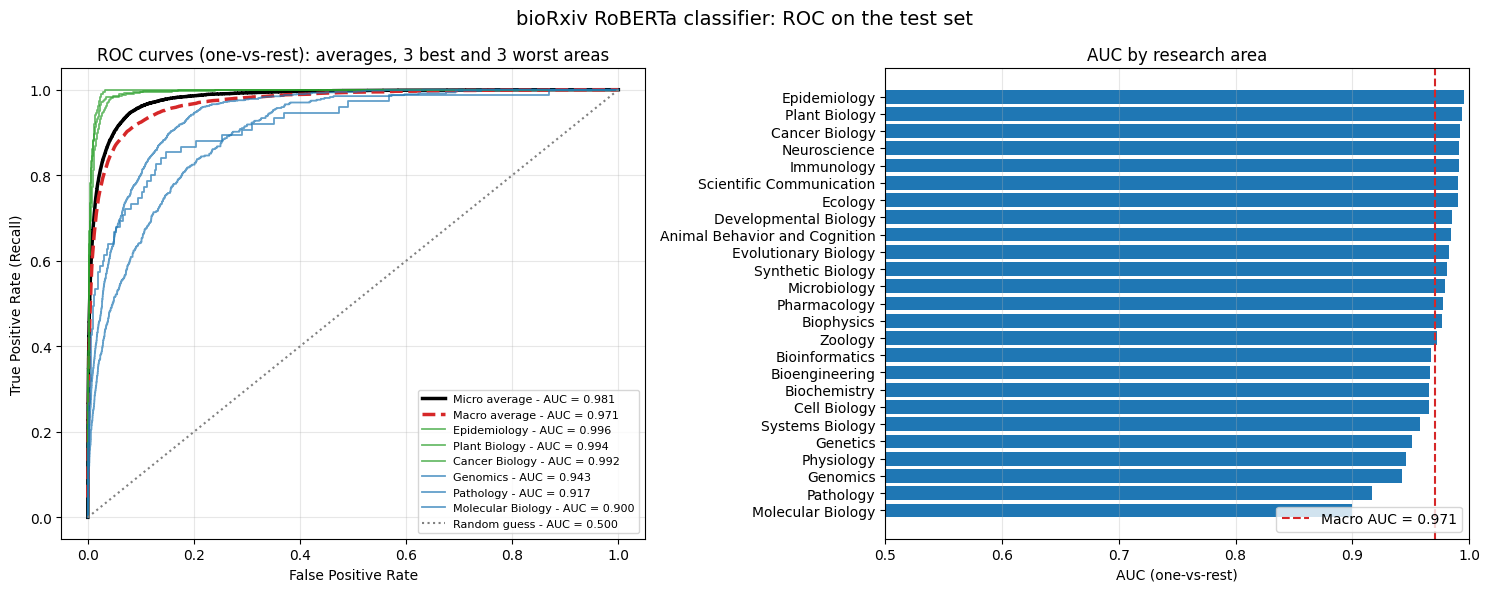

In [73]:
# plot averages, the three best and the three worst areas / plotar as médias e as três melhores e três piores áreas
ordered_classes = sorted(range(n_classes), key=lambda i: auc_by_class[i], reverse=True)
best_classes = ordered_classes[:3]
worst_classes = ordered_classes[-3:]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# left panel: averages and extreme areas / painel esquerdo: médias e áreas extremas
axes[0].plot(fpr_micro, tpr_micro, color="black", linewidth=2.5, label=f"Micro average - AUC = {auc_micro:.3f}")
axes[0].plot(fpr_grid, tpr_macro, color="tab:red", linewidth=2.5, linestyle="--", label=f"Macro average - AUC = {auc_macro:.3f}")
for class_idx in best_classes:
    axes[0].plot(fpr_by_class[class_idx], tpr_by_class[class_idx], color="tab:green", alpha=0.7, linewidth=1.3,
                 label=f"{label_names[class_idx]} - AUC = {auc_by_class[class_idx]:.3f}")
for class_idx in worst_classes:
    axes[0].plot(fpr_by_class[class_idx], tpr_by_class[class_idx], color="tab:blue", alpha=0.7, linewidth=1.3,
                 label=f"{label_names[class_idx]} - AUC = {auc_by_class[class_idx]:.3f}")
axes[0].plot([0, 1], [0, 1], color="gray", linestyle=":", label="Random guess - AUC = 0.500")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].set_title("ROC curves (one-vs-rest): averages, 3 best and 3 worst areas")
axes[0].legend(loc="lower right", fontsize=8)
axes[0].grid(alpha=0.3)

# right panel: AUC of every area / painel direito: AUC de cada área
sorted_table = auc_table.sort_values("auc")
axes[1].barh(sorted_table["area"], sorted_table["auc"], color="tab:blue")
axes[1].axvline(auc_macro, color="tab:red", linestyle="--", label=f"Macro AUC = {auc_macro:.3f}")
axes[1].set_xlim(0.5, 1.0)
axes[1].set_xlabel("AUC (one-vs-rest)")
axes[1].set_title("AUC by research area")
axes[1].legend(loc="lower right")
axes[1].grid(alpha=0.3, axis="x")

plt.suptitle("bioRxiv RoBERTa classifier: ROC on the test set", fontsize=14)
plt.tight_layout()

# save the figure to Drive for the README / salvar a figura no Drive para o README
plt.savefig(os.path.join(output_dir, "roc_curves.png"), dpi=150, bbox_inches="tight")
plt.show()

## ROC Analysis (One-vs-Rest)

**What the plot shows:** for each area $i$, the model's probability $s_i(x)$ is treated as a score for "area $i$ against all others". Sweeping a threshold $t$ gives

$$\mathrm{TPR}_i(t)=\frac{TP_i(t)}{s_i},\qquad \mathrm{FPR}_i(t)=\frac{FP_i(t)}{N-s_i}$$

with $s_i$ the support of area $i$, $N=14{,}893$ and $K=25$. The left panel draws these curves (averages, 3 best, 3 worst areas) and the right panel the area under each curve:

$$\mathrm{AUC}_i=\int_0^1 \mathrm{TPR}_i\,d\mathrm{FPR}_i=P\big(s_i(x^{+})>s_i(x^{-})\big)+\tfrac12 P\big(s_i(x^{+})=s_i(x^{-})\big)$$

That is, the probability that a random article of area $i$ gets a higher score than a random article of another area. Micro average pools all $N\cdot K$ article-area decisions, macro average takes the mean of the curves:

$$\mathrm{AUC}_{\text{macro}}=\frac1K\sum_{i=1}^{K}\mathrm{AUC}_i\approx0.971,\qquad \mathrm{AUC}_{\text{micro}}\approx0.981$$

### Observations

1. **Every area ranks well, and the spread is narrow.** AUC goes from 0.900 (Molecular Biology) to 0.996 (Epidemiology). About 15 of 25 areas are above the macro line. With the Gini coefficient $G_i=2\,\mathrm{AUC}_i-1$, the macro value is $G=0.942$, the worst area has $G=0.800$ and the best $G=0.992$. Compare this with F1, which spans 0.250 to 0.899 on the same areas. AUC separates areas much less than F1 does (observation 3 explains why).

2. **The error of the ranking is 1 − AUC, and it can be counted in pairs.** The number of (article of area $i$, article of another area) pairs is $s_i(N-s_i)$, and a fraction $1-\mathrm{AUC}_i$ of them is mis-ordered:

| Area | $s_i$ | $\mathrm{AUC}_i$ | Pairs $s_i(N-s_i)$ | Mis-ordered pairs |
|---|---|---|---|---|
| Epidemiology | 187 | 0.996 | 2.75 M | about 11 thousand |
| Pathology | 75 | 0.917 | 1.11 M | about 92 thousand |
| Molecular Biology | 468 | 0.900 | 6.75 M | about 675 thousand |

3. **A high AUC does not mean a high F1, because precision depends on prevalence.** Let $\pi_i=s_i/N$. A threshold with rates $(\mathrm{TPR},\mathrm{FPR})$ has

$$\mathrm{Precision}=\frac{\mathrm{TPR}\,\pi}{\mathrm{TPR}\,\pi+\mathrm{FPR}\,(1-\pi)},\qquad F_1=\frac{2\,\mathrm{TPR}\,\pi}{\pi\,(1+\mathrm{TPR})+\mathrm{FPR}\,(1-\pi)}$$

   The same ROC point gives very different precision in a rare and in a common area. Take $\mathrm{TPR}=0.8$ and $\mathrm{FPR}=0.10$ as an illustration (not read from the curves). With Molecular Biology's prevalence ($\pi=0.031$), precision is $0.8\cdot0.031/(0.8\cdot0.031+0.10\cdot0.969)\approx0.21$. With Neuroscience's prevalence ($\pi=0.183$), it is $\approx0.64$. The ROC curve is blind to this, since it never uses $\pi$.

4. **The model works at the far left of the curve, where AUC says little.** Rates at the argmax decision, recovered from precision and recall of the report ($TP=\mathrm{Recall}\cdot s$, $FP=TP(1-\mathrm{Prec})/\mathrm{Prec}$, $\mathrm{FPR}=FP/(N-s)$):

| Area | $\pi$ | AUC | FPR | TPR (recall) | Precision | $F_1$ (from the formula) |
|---|---|---|---|---|---|---|
| Neuroscience | 18.3% | about 0.991 | 1.4% | 0.867 | 0.933 | 0.899 |
| Genomics | 6.5% | 0.943 | 2.8% | 0.495 | 0.556 | 0.524 |
| Molecular Biology | 3.1% | 0.900 | 1.2% | 0.263 | 0.417 | 0.322 |
| Epidemiology | 1.3% | 0.996 | 0.5% | 0.786 | 0.653 | 0.714 |
| Zoology | 0.5% | 0.972 | 0.2% | 0.342 | 0.446 | 0.388 |
| Pathology | 0.5% | 0.917 | 0.1% | 0.173 | 0.448 | 0.250 |

   The $F_1$ column reproduces the report (0.899, 0.524, 0.322, 0.714, 0.388, 0.250), so the rates are consistent. All operating points have $\mathrm{FPR}\le2.8\%$. The AUC integrates over the whole range up to $\mathrm{FPR}=1$, but only the leftmost few percent is ever used. The relevant quantity is the partial area $\mathrm{pAUC}(f)=\int_0^{f}\mathrm{TPR}\,d\mathrm{FPR}$ with $f\approx0.03$, which is not shown in the plot.

5. **The operating points likely sit below their own ROC curves.** Epidemiology reaches $\mathrm{AUC}=0.996$, which implies a much higher TPR than 0.786 at $\mathrm{FPR}=0.5\%$. The reason is that the argmax rule does not apply one threshold to $s_i$. Article $x$ goes to area $i$ only if $s_i(x)>s_j(x)$ for all $j\ne i$, so an article with a high Epidemiology score is lost when a neighbor scores higher. The ROC measures the ranking of $s_i$ alone, and the classification also depends on the competition between areas. This is a hypothesis, and the code below checks it by computing the best one-vs-rest threshold per area.

6. **How many false positives each area can afford.** For the precision to stay at or above 0.5 with $\mathrm{TPR}=0.8$, we need $FP\le TP$, which gives

$$\mathrm{FPR}_{\max}=\frac{0.8\,s_i}{N-s_i}$$

| Area | Allowed false positives | $\mathrm{FPR}_{\max}$ |
|---|---|---|
| Neuroscience | about 2,180 | 17.9% |
| Molecular Biology | about 374 | 2.6% |
| Epidemiology | about 150 | 1.0% |
| Pathology | about 60 | 0.4% |

   For Pathology, the model must be right about 60 of 75 articles and wrong about no more than 60 of 14,818 others. This is a very small error budget, even for an area with $\mathrm{AUC}=0.917$.

7. **Small areas have jagged curves and wide intervals.** Each positive article moves the curve up by $1/s_i$: 0.0133 for Pathology and 0.0004 for Neuroscience. This is the staircase visible in the Pathology curve. With the Hanley-McNeil standard error (derived from $n^{+}=s_i$ and $n^{-}=N-s_i$), the 95% intervals are approximately:

| Area | AUC | 95% interval |
|---|---|---|
| Epidemiology | 0.996 | ±0.006 |
| Genomics | 0.943 | ±0.010 |
| Molecular Biology | 0.900 | ±0.019 |
| Pathology | 0.917 | ±0.043 |

   Genomics (0.933 to 0.953) is clearly above Molecular Biology (0.881 to 0.919). Pathology (0.874 to 0.960) overlaps with both, so its position as second-worst is not statistically settled.

8. **A common scale for how separable each area is.** Assuming normal scores with equal variance (the binormal model), $\mathrm{AUC}=\Phi(d'/\sqrt2)$, so

$$d'=\sqrt2\,\Phi^{-1}(\mathrm{AUC})$$

   This gives $d'\approx1.81$ for Molecular Biology, 1.96 for Pathology, 2.23 for Genomics, 2.68 at the macro value and 3.75 for Epidemiology. The assumption is rough, since softmax scores are not normal, but it shows that Epidemiology is about twice as separable as Molecular Biology in standard-deviation units.

9. **Micro AUC is higher than macro AUC.** The pooled problem has $N=14{,}893$ positive decisions and $N(K-1)=357{,}432$ negative ones, a ratio of 1 to 24. Large areas, which also have high AUC, weigh more in the micro average, and the pooling also rewards scores that are comparable across areas, which the softmax gives. The gap is $0.981-0.971=0.010$. This is the likely explanation, but it is not tested here.

### Limits of this analysis

| Limit | Consequence |
|---|---|
| Values read from a figure | AUC values are accurate to about ±0.003, and the Neuroscience value is approximate |
| Hanley-McNeil assumes smooth score distributions | Intervals are rough for very small areas, and bootstrap would be safer |
| Single run, single seed | Differences of a few thousandths between areas can be noise |
| One label per article | Overlapping areas lower AUC without being model errors |
| Points 5 and 9 are hypotheses | They need the per-area threshold check and the pooled computation |

### Decisions taken from this plot

| Decision | Reason |
|---|---|
| Report macro AUC (0.971) only next to macro F1 (0.624) | AUC alone suggests a near-perfect model, and the gap measures the cost of prevalence and competition between areas |
| Evaluate with precision-recall curves per area | They use prevalence, so they show the rare areas honestly |
| Report the partial AUC for $\mathrm{FPR}\le0.03$ | It covers the region where the model really operates |
| Treat the Pathology position as undetermined | Its interval is ±0.043 |
| Test per-area thresholds on validation, never on test | Thresholds tuned on test would inflate the results |

# Part 11 - Save model

In [75]:
"""bioRxiv v2 - model saving and prediction examples.

Confirma o modelo salvo, guarda o mapeamento de áreas e mostra previsões de artigos do teste.
"""

import json
import os
import numpy as np
import torch

# stop with a clear message if the evaluation outputs are missing / parar com mensagem clara se as saídas da avaliação não existem
if "test_probs" not in globals() or "y_true" not in globals():
    test_output = trainer.predict(datasets_by_split["test"])
    y_true = test_output.label_ids
    test_probs = torch.softmax(torch.tensor(test_output.predictions), dim=-1).numpy()

# save model and tokenizer to the v2 folder in Drive / salvar modelo e tokenizer na pasta v2 do Drive
best_dir = os.path.join(output_dir, "best")
trainer.save_model(best_dir)
tokenizer.save_pretrained(best_dir)

# save the area mapping next to the model / salvar o mapeamento de áreas ao lado do modelo
with open(os.path.join(best_dir, "area_mapping.json"), "w", encoding="utf-8") as f:
    json.dump({"label2id": label2id, "id2label": {str(k): v for k, v in id2label.items()}}, f, ensure_ascii=False, indent=2)
print("model saved to", best_dir)
print("files:", sorted(os.listdir(best_dir)))

# predictions keep the order of test_df / as previsões mantêm a ordem do test_df
assert len(test_df) == len(test_probs), "test_df and predictions have different sizes"

# show 8 random test articles with the top-3 predicted areas / mostrar 8 artigos de teste aleatórios com as três áreas mais prováveis
rng = np.random.default_rng(7)
for row_idx in rng.choice(len(test_df), size=8, replace=False):
    top3_idx = np.argsort(test_probs[row_idx])[::-1][:3]
    true_area = label_names[y_true[row_idx]]
    hit = "correct" if top3_idx[0] == y_true[row_idx] else "wrong"
    print(f"{test_df.loc[row_idx, 'title'][:100]}")
    print(f"   true area: {true_area} | top-1: {hit}")
    for idx in top3_idx:
        print(f"   {label_names[idx]}: {test_probs[row_idx][idx]:.3f}")
    print()

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

model saved to /content/drive/MyDrive/biorxiv_classifier/roberta_classifier_v2/best
files: ['area_mapping.json', 'config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']
Early-life social environment alters juvenile behavior and neuroendocrine function in a highly socia
   true area: Neuroscience | top-1: wrong
   Animal Behavior and Cognition: 0.751
   Neuroscience: 0.215
   Developmental Biology: 0.005

The Equidistance Index of Population Structure
   true area: Evolutionary Biology | top-1: correct
   Evolutionary Biology: 0.933
   Genetics: 0.027
   Ecology: 0.018

Cell Remote Mechanics Regulates Large-spatial Isotropic Matrix Modeling with Dynamic Simulations
   true area: Biophysics | top-1: correct
   Biophysics: 0.641
   Bioengineering: 0.202
   Cell Biology: 0.052

Resolution of conflict between parental genomes in a hybrid species
   true area: Evolutionary Biology | top-1: correct
   Evolutionary Biology: 0.985
   Genetics: 0.008
 

In [76]:
"""bioRxiv v2 - confident errors.

Lista os artigos errados em que o modelo tinha mais confiança, para checar rótulos duvidosos.
"""

import pandas as pd

# predicted area and its probability for every test article / área prevista e sua probabilidade para cada artigo de teste
pred_idx = test_probs.argmax(axis=-1)
errors_df = pd.DataFrame(
    {
        "title": test_df["title"].str[:90].values,
        "true_area": [label_names[i] for i in y_true],
        "predicted_area": [label_names[i] for i in pred_idx],
        "confidence": test_probs.max(axis=-1).round(3),
    }
)
errors_df = errors_df[errors_df["true_area"] != errors_df["predicted_area"]]
print("errors:", len(errors_df), "of", len(test_df))
print(errors_df.sort_values("confidence", ascending=False).head(20).to_string(index=False))

errors: 4424 of 14893
                                                                                     title                     true_area       predicted_area  confidence
                              Lag Effects in Primate Brain Size Evolution: A Re-Evaluation Animal Behavior and Cognition Evolutionary Biology       0.994
Disrupted cholinergic modulation can underlie abnormal gamma rhythms in schizophrenia and                      Pathology         Neuroscience       0.994
Lack of negative density-dependence regulation in a dominant oak tree from a neotropical h                 Plant Biology              Ecology       0.994
The Limits to Parapatric Speciation II: Strengthening a Preexisting Genetic Barrier to Gen                      Genetics Evolutionary Biology       0.993
Resurrection of the island rule – human-driven extinctions have obscured a basic evolution                       Ecology Evolutionary Biology       0.991
    Quantifying the impact of ecological memory on the

# **Part 12 - Predictions using a trained model**

In [77]:
"""EPIC-QA - load the fine-tuned cross-encoder for inference.

Carrega o modelo ajustado salvo no Drive e o coloca em modo de inferência.
"""

# load the fine-tuned model and tokenizer from Drive / carregar o modelo ajustado e o tokenizer do Drive
model_dir = r"/content/drive/MyDrive/epicqa_model/best"
rerank_tokenizer = AutoTokenizer.from_pretrained(model_dir)
rerank_model = AutoModelForSequenceClassification.from_pretrained(model_dir).to("cuda").half().eval()
print("model loaded")

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

model loaded


In [78]:
# recompute test probabilities if they are not in memory / recalcular as probabilidades de teste se não estiverem na memória
if "test_probs" not in globals() or "y_true" not in globals():
    test_output = trainer.predict(datasets_by_split["test"])
    y_true = test_output.label_ids
    test_probs = torch.softmax(torch.tensor(test_output.predictions), dim=-1).numpy()

# predictions keep the order of test_df / as previsões mantêm a ordem do test_df
assert len(test_df) == len(test_probs), "test_df and predictions have different sizes"

# top-3 areas and probabilities per article / três áreas mais prováveis e probabilidades por artigo
top3_idx = np.argsort(test_probs, axis=-1)[:, ::-1][:, :3]
predictions_df = pd.DataFrame(
    {
        "article_id": test_df["article_id"].values,
        "title": test_df["title"].values,
        "true_area": [label_names[i] for i in y_true],
        "pred_1": [label_names[row[0]] for row in top3_idx],
        "prob_1": [round(float(test_probs[n, row[0]]), 4) for n, row in enumerate(top_idx for top_idx in top3_idx)],
        "pred_2": [label_names[row[1]] for row in top3_idx],
        "prob_2": [round(float(test_probs[n, row[1]]), 4) for n, row in enumerate(top3_idx)],
        "pred_3": [label_names[row[2]] for row in top3_idx],
        "prob_3": [round(float(test_probs[n, row[2]]), 4) for n, row in enumerate(top3_idx)],
    }
)
predictions_df["top1_correct"] = predictions_df["true_area"] == predictions_df["pred_1"]
predictions_df["top3_correct"] = [
    predictions_df.loc[n, "true_area"] in (predictions_df.loc[n, "pred_1"], predictions_df.loc[n, "pred_2"], predictions_df.loc[n, "pred_3"])
    for n in range(len(predictions_df))
]

# save to Drive / salvar no Drive
predictions_df.to_csv(os.path.join(output_dir, "test_predictions.csv"), index=False)
print("top-1 accuracy:", round(predictions_df["top1_correct"].mean(), 4))
print("top-3 accuracy:", round(predictions_df["top3_correct"].mean(), 4))
predictions_df.head(10)

top-1 accuracy: 0.7026
top-3 accuracy: 0.9215


,article_id,title,true_area,pred_1,prob_1,pred_2,prob_2,pred_3,prob_3,top1_correct,top3_correct
0,037713,A genetic test for differential causative path...,Genomics,Genetics,0.7650,Genomics,0.1996,Bioinformatics,0.0227,False,True
1,939975,Collective sperm movements in Peromyscus mice ...,Evolutionary Biology,Evolutionary Biology,0.9393,Biophysics,0.0138,Animal Behavior and Cognition,0.0126,True,True
2,351973,An atomic-scale view at the composition of amy...,Biochemistry,Biophysics,0.9187,Biochemistry,0.0495,Molecular Biology,0.0139,False,True
3,180240,Signal complexity of human intracranial EEG tr...,Neuroscience,Neuroscience,0.9907,Animal Behavior and Cognition,0.0031,Bioengineering,0.0020,True,True
4,102129,Bayesian Divergence-Time Estimation with Genom...,Evolutionary Biology,Evolutionary Biology,0.9524,Genomics,0.0347,Genetics,0.0051,True,True
5,296194,Pathological Oxidation of PTPN12 Underlies ABL...,Cancer Biology,Cancer Biology,0.7982,Biochemistry,0.0803,Molecular Biology,0.0510,True,True
6,062307,An Empirical Analysis of Topic Modeling for Mi...,Bioinformatics,Bioinformatics,0.8731,Genomics,0.0442,Cancer Biology,0.0244,True,True
7,047092,Terraces in Gene Tree Reconciliation-Based Spe...,Evolutionary Biology,Evolutionary Biology,0.5129,Bioinformatics,0.4252,Genomics,0.0308,True,True
8,264804,Morphometric analysis of spread platelets iden...,Cell Biology,Cell Biology,0.8033,Biophysics,0.1037,Biochemistry,0.0250,True,True
9,487126,Can the Insect Path Integration Memory be a Bu...,Animal Behavior and Cognition,Animal Behavior and Cognition,0.8610,Neuroscience,0.1240,Evolutionary Biology,0.0026,True,True


In [79]:
"""bioRxiv v2 - save predictions and top-k accuracy.

Salva as previsões do teste no Drive e calcula acerto top-1 e top-3, no geral e por área.
"""

# stop with a clear message if the predictions table is missing / parar com mensagem clara se a tabela de previsões não existe
required_columns = {"true_area", "pred_1", "top1_correct", "top3_correct"}
if "predictions_df" not in globals() or not required_columns.issubset(predictions_df.columns):
    raise RuntimeError("Run the bioRxiv predictions table cell first: this predictions_df is not the article-level one.")

# save predictions to the v2 folder in Drive / salvar as previsões na pasta v2 do Drive
predictions_df.to_csv(os.path.join(output_dir, "test_predictions.csv"), index=False)

# overall top-k accuracy / acerto top-k geral
print("top-1 accuracy:", round(predictions_df["top1_correct"].mean(), 4))
print("top-3 accuracy:", round(predictions_df["top3_correct"].mean(), 4))
print(predictions_df.shape)

# top-1 and top-3 accuracy per true area, with support / acerto top-1 e top-3 por área real, com suporte
per_area_df = (
    predictions_df.groupby("true_area")
    .agg(articles=("top1_correct", "size"), top1=("top1_correct", "mean"), top3=("top3_correct", "mean"))
    .sort_values("top1", ascending=False)
    .round(3)
)
print(per_area_df.to_string())

top-1 accuracy: 0.7026
top-3 accuracy: 0.9215
(14893, 11)
                               articles   top1   top3
true_area                                            
Neuroscience                       2722  0.868  0.967
Plant Biology                       435  0.846  0.968
Ecology                             666  0.802  0.964
Cancer Biology                      505  0.796  0.943
Immunology                          448  0.788  0.940
Epidemiology                        187  0.781  0.963
Evolutionary Biology               1056  0.777  0.958
Scientific Communication             93  0.742  0.903
Biophysics                          649  0.740  0.948
Microbiology                       1212  0.734  0.935
Animal Behavior and Cognition       248  0.734  0.948
Bioinformatics                     1550  0.708  0.915
Developmental Biology               436  0.695  0.897
Synthetic Biology                   137  0.679  0.854
Cell Biology                        731  0.633  0.929
Genetics                

In [80]:
"""bioRxiv v2 - prediction examples for sample areas.

Mostra artigos de teste de três áreas com as três áreas previstas, separando acertos e erros.
"""

# stop with a clear message if this is not the article-level table / parar com mensagem clara se esta não é a tabela por artigo
required_columns = {"true_area", "pred_1", "prob_1", "pred_2", "prob_2", "pred_3", "prob_3", "top1_correct"}
if "predictions_df" not in globals() or not required_columns.issubset(predictions_df.columns):
    raise RuntimeError("Run the bioRxiv predictions table cell first: this predictions_df is not the article-level one.")

# three random areas with at least 50 test articles / três áreas aleatórias com pelo menos 50 artigos de teste
area_sizes = predictions_df["true_area"].value_counts()
eligible_areas = area_sizes[area_sizes >= 50].index.tolist()
sample_areas = pd.Series(eligible_areas).sample(3, random_state=7).tolist()

for area in sample_areas:
    block = predictions_df[predictions_df["true_area"] == area]
    print(area, "|", len(block), "articles | top-1 accuracy:", round(block["top1_correct"].mean(), 3))

    # two correct and two wrong examples per area / dois exemplos corretos e dois errados por área
    for is_correct, label in [(True, "correct"), (False, "wrong")]:
        subset = block[block["top1_correct"] == is_correct]
        for _, row in subset.sample(min(2, len(subset)), random_state=7).iterrows():
            print(f"  [{label}] {row['title'][:100]}")
            print(f"     {row['pred_1']}: {row['prob_1']:.3f} | {row['pred_2']}: {row['prob_2']:.3f} | {row['pred_3']}: {row['prob_3']:.3f}")
    print()

Bioinformatics | 1550 articles | top-1 accuracy: 0.708
  [correct] Wisdom of artificial crowds feature selection in untargeted metabolomics: An application to the deve
     Bioinformatics: 0.832 | Systems Biology: 0.069 | Biochemistry: 0.024
  [correct] Random forest based similarity learning for single cell RNA sequencing data
     Bioinformatics: 0.961 | Genomics: 0.034 | Systems Biology: 0.001
  [wrong] Proteome Exploration of Legionella pneumophila for Identifying Novel Therapuetics: A Hierarchical Su
     Systems Biology: 0.540 | Bioinformatics: 0.199 | Microbiology: 0.143
  [wrong] Functional Connectomics from Data: Probabilistic Graphical Models for Neuronal Network of C. elegans
     Neuroscience: 0.842 | Systems Biology: 0.054 | Bioinformatics: 0.035

Cell Biology | 731 articles | top-1 accuracy: 0.633
  [correct] Translation of cellular protein localization by generative adversarial network
     Cell Biology: 0.547 | Bioinformatics: 0.332 | Systems Biology: 0.029
  [correct] 

In [81]:
# load the saved model, tokenizer and area mapping / carregar o modelo salvo, o tokenizer e o mapeamento de áreas
best_dir = r"/content/drive/MyDrive/biorxiv_classifier/roberta_classifier_v2/best"
if not os.path.isdir(best_dir):
    raise FileNotFoundError("Saved model not found. Run the fine-tuning cell and the save cell first.")

new_tokenizer = AutoTokenizer.from_pretrained(best_dir)
new_model = AutoModelForSequenceClassification.from_pretrained(best_dir, dtype=torch.bfloat16).to("cuda").eval()
area_names = [new_model.config.id2label[i] for i in range(new_model.config.num_labels)]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

In [82]:
# articles to classify: title and abstract / artigos para classificar: título e resumo
new_articles = [
    {
        "title": "Place cell remapping in the mouse hippocampus during spatial learning",
        "abstract": "We recorded neuronal activity in the mouse hippocampus during spatial navigation and found that place cells remapped after learning a new environment.",
    },
    {
        "title": "Genome assembly of a multidrug-resistant bacterial isolate",
        "abstract": "We assembled the genome of a novel bacterial isolate and identified antibiotic resistance genes located on a conjugative plasmid.",
    },
]

In [83]:

# tokenize title and abstract as a text pair / tokenizar título e resumo como par de textos
inputs = new_tokenizer(
    [article["title"] for article in new_articles],
    [article["abstract"] for article in new_articles],
    truncation="only_second",
    max_length=384,
    padding=True,
    return_tensors="pt",
).to("cuda")

# probabilities for every area / probabilidades para cada área
with torch.no_grad():
    probabilities = torch.softmax(new_model(**inputs).logits.float(), dim=-1).cpu().numpy()

# print the three most likely areas per article / imprimir as três áreas mais prováveis por artigo
for article, probs in zip(new_articles, probabilities):
    print(article["title"])
    for idx in np.argsort(probs)[::-1][:3]:
        print(f"   {area_names[idx]}: {probs[idx]:.3f}")
    print()

Place cell remapping in the mouse hippocampus during spatial learning
   Neuroscience: 0.777
   Animal Behavior and Cognition: 0.089
   Bioengineering: 0.011

Genome assembly of a multidrug-resistant bacterial isolate
   Genomics: 0.801
   Microbiology: 0.105
   Bioinformatics: 0.056



# **Part 13 - RAG Model bioRxiv**

In [84]:
"""bioRxiv RAG - setup and article loading.

Monta o Drive, autentica no Hugging Face e carrega os artigos já extraídos dos XMLs.
"""

import gc
import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from google.colab import drive, userdata
from huggingface_hub import login

from transformers import (
    AutoTokenizer,
    AutoModel,
    AutoModelForSequenceClassification,
    AutoModelForCausalLM,
)

In [86]:
# mount Drive only if it is not mounted yet / montar o Drive só se ainda não estiver montado
if not os.path.isdir(r"/content/drive/MyDrive"):
    drive.mount("/content/drive")

# paths and model names / caminhos e nomes dos modelos
work_dir = r"/content/drive/MyDrive/biorxiv_classifier"
rag_dir = os.path.join(work_dir, "rag")
os.makedirs(rag_dir, exist_ok=True)
articles_path = os.path.join(work_dir, "articles_full_v2.parquet")
embeddings_path = os.path.join(rag_dir, "bge_large_abstract_embeddings.pt")
embedder_name = "BAAI/bge-large-en-v1.5"
reranker_name = "BAAI/bge-reranker-large"
llm_name = "Qwen/Qwen2.5-14B-Instruct"

In [87]:
# bge instruction prefix applied only to queries / prefixo de instrução do bge aplicado apenas às consultas
query_prefix = "Represent this sentence for searching relevant passages: "

# stop with a clear message if the parsed articles are missing / parar com mensagem clara se os artigos extraídos não existem
if not os.path.exists(articles_path):
    raise FileNotFoundError("articles_full_v2.parquet not found. Run the parallel XML parsing cell (v2) first.")

# keep articles with a title and enough abstract text / manter artigos com título e resumo suficiente
articles_df = pd.read_parquet(articles_path)
articles_df["abstract_words"] = articles_df["abstract"].str.split().str.len().fillna(0)
articles_df = articles_df[
    (articles_df["abstract_words"] >= 30) & (articles_df["title"].str.len() > 0)
].reset_index(drop=True)

print(articles_df.shape)
print("articles with research area:", int((articles_df["subject"] != "").sum()))
print(torch.cuda.get_device_name(0))

(99540, 6)
articles with research area: 99515
NVIDIA RTX PRO 6000 Blackwell Server Edition


In [88]:
"""bioRxiv RAG - load embedder, reranker and generator.

Carrega o bge-large (busca), o bge-reranker-large (reordenação) e o Qwen2.5 14B (geração).
"""

# free GPU memory from previous models / liberar a memória da GPU de modelos anteriores
for old_name in ["model", "trainer", "new_model", "reader_model"]:
    if old_name in globals():
        del globals()[old_name]
gc.collect()
torch.cuda.empty_cache()

# bge-large embedder in half precision / embedder bge-large em meia precisão
embed_tokenizer = AutoTokenizer.from_pretrained(embedder_name)
embed_model = AutoModel.from_pretrained(embedder_name, dtype=torch.float16).to("cuda").eval()

# bge reranker cross-encoder / cross-encoder bge reranker
rerank_tokenizer = AutoTokenizer.from_pretrained(reranker_name)
rerank_model = AutoModelForSequenceClassification.from_pretrained(
    reranker_name, dtype=torch.float16
).to("cuda").eval()

# Qwen2.5 generator in bfloat16 / gerador Qwen2.5 em bfloat16
llm_tokenizer = AutoTokenizer.from_pretrained(llm_name)
llm_model = AutoModelForCausalLM.from_pretrained(
    llm_name,
    dtype=torch.bfloat16,
    device_map="auto",
)

allocated_gb = torch.cuda.memory_allocated() / (1024 ** 3)
total_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
print(f"{allocated_gb:.1f} GB allocated of {total_gb:.1f} GB")

config.json:   0%|          | 0.00/779 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/366 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/579 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

29.2 GB allocated of 95.0 GB


In [89]:
"""bioRxiv RAG - abstract embeddings with Drive cache.

Codifica os resumos com o bge-large e guarda a matriz de vetores no Drive.
"""

pool_embeddings = None

# reuse the cache only if it matches this corpus and model / reutilizar o cache apenas se bater com este corpus e modelo
if os.path.exists(embeddings_path):
    cached = torch.load(embeddings_path)
    if (
        cached["model"] == embedder_name
        and cached["count"] == len(articles_df)
        and cached["first_id"] == articles_df.loc[0, "article_id"]
    ):
        pool_embeddings = cached["embeddings"].to("cuda")
        print("loaded cached embeddings:", tuple(pool_embeddings.shape))

if pool_embeddings is None:
    # documents are the abstracts only, so title queries are a fair test / os documentos são só os resumos, então consultas por título são um teste justo
    texts = articles_df["abstract"].tolist()

    # sort by length to reduce padding / ordenar por tamanho para reduzir padding
    order = np.argsort([len(text) for text in texts])
    pool_embeddings = torch.zeros((len(texts), 1024), dtype=torch.float16, device="cuda")
    batch_size = 256

    # encode in batches with CLS pooling and L2 normalization / codificar em lotes com pooling CLS e normalização L2
    for start in tqdm(range(0, len(texts), batch_size)):
        batch_idx = order[start:start + batch_size]
        inputs = embed_tokenizer(
            [texts[i] for i in batch_idx],
            truncation=True,
            max_length=512,
            padding=True,
            return_tensors="pt",
        ).to("cuda")
        with torch.no_grad():
            cls_vectors = embed_model(**inputs).last_hidden_state[:, 0, :]
        pool_embeddings[torch.tensor(batch_idx, device="cuda")] = F.normalize(cls_vectors.float(), dim=-1).half()

    torch.save(
        {
            "model": embedder_name,
            "count": len(articles_df),
            "first_id": articles_df.loc[0, "article_id"],
            "embeddings": pool_embeddings.cpu(),
        },
        embeddings_path,
    )
    print("encoded and cached:", tuple(pool_embeddings.shape))

loaded cached embeddings: (99540, 1024)


In [90]:
"""bioRxiv RAG - ask questions.

Recupera os resumos mais próximos, reordena e gera respostas com fontes citadas.
"""

# questions to answer / perguntas para responder
my_questions = [
    "What brain regions are involved in spatial navigation?",
    "How does antibiotic resistance spread between bacteria?",
]

# optional filter by research area, None searches every area / filtro opcional por área de pesquisa, None busca em todas as áreas
area_filter = None

# retrieval and context settings / parâmetros de recuperação e contexto
n_retrieve = 100
n_context = 6
answer_rows = []

# boolean mask on the GPU for the area filter / máscara booleana na GPU para o filtro de área
area_mask = None
if area_filter is not None:
    area_mask = torch.tensor((articles_df["subject"] == area_filter).values, device="cuda")
    if int(area_mask.sum()) == 0:
        raise ValueError(f"No articles found for area '{area_filter}'.")

for rag_question in my_questions:
    # encode the query with the bge instruction prefix / codificar a consulta com o prefixo de instrução do bge
    q_inputs = embed_tokenizer(
        query_prefix + rag_question, truncation=True, max_length=128, return_tensors="pt"
    ).to("cuda")
    with torch.no_grad():
        q_vector = F.normalize(embed_model(**q_inputs).last_hidden_state[:, 0, :].float(), dim=-1).half()
        similarities = (pool_embeddings @ q_vector.T).squeeze(-1)
        if area_mask is not None:
            similarities = similarities.masked_fill(~area_mask, -1e4)
    top_idx = torch.topk(similarities, k=min(n_retrieve, len(articles_df))).indices.cpu().numpy()
    candidates = articles_df.iloc[top_idx].reset_index(drop=True)

    # rerank the candidates / reordenar as candidatas
    r_inputs = rerank_tokenizer(
        [rag_question] * len(candidates),
        candidates["abstract"].tolist(),
        truncation=True,
        max_length=512,
        padding=True,
        return_tensors="pt",
    ).to("cuda")
    with torch.no_grad():
        rerank_scores = rerank_model(**r_inputs).logits.squeeze(-1).float().cpu().numpy()
    best = np.argsort(rerank_scores)[::-1][:n_context]

    # grounded prompt with numbered sources and titles / prompt ancorado com fontes numeradas e títulos
    context_block = "\n\n".join(
        f"[{number}] Title: {candidates.loc[i, 'title']}\nAbstract: {candidates.loc[i, 'abstract']}"
        for number, i in enumerate(best, start=1)
    )
    messages = [
        {
            "role": "system",
            "content": (
                "You are a biomedical research assistant. Answer using ONLY the numbered sources provided. "
                "Cite sources inline like [1], [2]. If the sources do not contain enough information, "
                "say so clearly. Do not use outside knowledge."
            ),
        },
        {"role": "user", "content": f"Sources:\n{context_block}\n\nQuestion: {rag_question}"},
    ]

    # chat template returns a dict in transformers 5.x / o chat template retorna um dicionário no transformers 5.x
    chat_inputs = llm_tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True,
    ).to(llm_model.device)
    prompt_length = chat_inputs["input_ids"].shape[1]
    with torch.no_grad():
        output_ids = llm_model.generate(
            **chat_inputs,
            max_new_tokens=400,
            do_sample=False,
            pad_token_id=llm_tokenizer.eos_token_id,
        )
    rag_answer = llm_tokenizer.decode(output_ids[0][prompt_length:], skip_special_tokens=True).strip()

    # print answer and sources / imprimir resposta e fontes
    print("Question:", rag_question)
    print()
    print(rag_answer)
    print()
    print("Sources:")
    for number, i in enumerate(best, start=1):
        print(f"[{number}] score={rerank_scores[i]:.2f} | {candidates.loc[i, 'subject']} | {candidates.loc[i, 'title'][:90]} | doi: {candidates.loc[i, 'doi']}")
    print()

    answer_rows.append(
        {
            "question": rag_question,
            "area_filter": area_filter or "",
            "answer": rag_answer,
            "sources": " | ".join(candidates.loc[i, "doi"] for i in best),
        }
    )

# save answers to Drive / salvar as respostas no Drive
pd.DataFrame(answer_rows).to_csv(os.path.join(rag_dir, "rag_answers.csv"), index=False)

Question: What brain regions are involved in spatial navigation?

Based on the provided sources, several brain regions are involved in spatial navigation:

1. **Hippocampus**: It plays a significant role in spatial navigation, as indicated by its involvement in encoding spatial walking directions [2].
2. **Subicular Complex (SC)**: This region shows a global cue-controlled, highly coherent representation of the environment, suggesting it might provide a "reference map" for spatial navigation [1].
3. **Retrosplenial Cortex (RSC)**: Like the hippocampus, this area also shows enhanced specificity of neural representations of walking direction after L-DOPA administration, although this enhancement is observed primarily in younger adults [2].
4. **Parahippocampal Cortex**: Contains "anchor cells" that represent egocentric directions towards proximal anchor points, facilitating egocentric navigation strategies [5].
5. **Somatosensory Cortex**: Identified as a novel site for a navigational sy

In [91]:
"""bioRxiv RAG - retrieval evaluation by title.

Mede se o resumo correto aparece no top-k quando a consulta é o título, antes e depois da reordenação.
"""

# sample articles with a reasonably long title / amostrar artigos com título razoavelmente longo
eval_pool = articles_df[articles_df["title"].str.len() > 30]
sample_idx = eval_pool.sample(min(300, len(eval_pool)), random_state=42).index.tolist()

ks = [1, 5, 10]
hits_retrieval = {k: 0 for k in ks}
hits_rerank = {k: 0 for k in ks}

for article_idx in tqdm(sample_idx):
    query = articles_df.loc[article_idx, "title"]

    # retrieve candidates on the GPU / recuperar candidatas na GPU
    q_inputs = embed_tokenizer(query_prefix + query, truncation=True, max_length=128, return_tensors="pt").to("cuda")
    with torch.no_grad():
        q_vector = F.normalize(embed_model(**q_inputs).last_hidden_state[:, 0, :].float(), dim=-1).half()
        similarities = (pool_embeddings @ q_vector.T).squeeze(-1)
    top_idx = torch.topk(similarities, k=100).indices.cpu().numpy()

    # rerank the candidates / reordenar as candidatas
    r_inputs = rerank_tokenizer(
        [query] * len(top_idx),
        articles_df.iloc[top_idx]["abstract"].tolist(),
        truncation=True,
        max_length=512,
        padding=True,
        return_tensors="pt",
    ).to("cuda")
    with torch.no_grad():
        rerank_scores = rerank_model(**r_inputs).logits.squeeze(-1).float().cpu().numpy()
    reranked_idx = top_idx[np.argsort(rerank_scores)[::-1]]

    # count a hit if the source article is in the top-k / contar acerto se o artigo de origem está no top-k
    for k in ks:
        if article_idx in top_idx[:k]:
            hits_retrieval[k] += 1
        if article_idx in reranked_idx[:k]:
            hits_rerank[k] += 1

results = pd.DataFrame(
    {
        "k": ks,
        "recall_retrieval": [hits_retrieval[k] / len(sample_idx) for k in ks],
        "recall_rerank": [hits_rerank[k] / len(sample_idx) for k in ks],
    }
)
print(results.round(3).to_string(index=False))

  0%|          | 0/300 [00:00<?, ?it/s]

 k  recall_retrieval  recall_rerank
 1             0.747          0.703
 5             0.970          0.977
10             0.990          0.997


In [92]:
"""bioRxiv RAG - save the pipeline configuration.

Salva os parâmetros, os nomes dos modelos e o prompt do RAG; opcionalmente copia os modelos menores.
"""

import json
import os

# folder of the saved pipeline / pasta do pipeline salvo
rag_dir = r"/content/drive/MyDrive/biorxiv_classifier/rag"
os.makedirs(rag_dir, exist_ok=True)

# system prompt used by the generator / prompt de sistema usado pelo gerador
system_prompt = (
    "You are a biomedical research assistant. Answer using ONLY the numbered sources provided. "
    "Cite sources inline like [1], [2]. If the sources do not contain enough information, "
    "say so clearly. Do not use outside knowledge."
)

# everything needed to rebuild the pipeline / tudo o que é preciso para reconstruir o pipeline
rag_config = {
    "embedder_name": embedder_name,
    "reranker_name": reranker_name,
    "llm_name": llm_name,
    "query_prefix": query_prefix,
    "n_retrieve": 100,
    "n_context": 6,
    "max_new_tokens": 400,
    "articles_path": articles_path,
    "embeddings_path": embeddings_path,
    "articles_count": int(len(articles_df)),
    "first_article_id": str(articles_df.loc[0, "article_id"]),
    "system_prompt": system_prompt,
}
with open(os.path.join(rag_dir, "rag_config.json"), "w", encoding="utf-8") as f:
    json.dump(rag_config, f, ensure_ascii=False, indent=2)
print("config saved to", os.path.join(rag_dir, "rag_config.json"))

# optional: copy the small models so they load without downloading / opcional: copiar os modelos menores para carregar sem baixar
save_small_models = True
if save_small_models:
    embed_tokenizer.save_pretrained(os.path.join(rag_dir, "embedder"))
    embed_model.save_pretrained(os.path.join(rag_dir, "embedder"))
    rerank_tokenizer.save_pretrained(os.path.join(rag_dir, "reranker"))
    rerank_model.save_pretrained(os.path.join(rag_dir, "reranker"))
    print("embedder and reranker saved")

# list saved files with sizes / listar os arquivos salvos com tamanhos
for root_dir, dirs, files in os.walk(rag_dir):
    for file_name in sorted(files):
        file_path = os.path.join(root_dir, file_name)
        print(f"{os.path.relpath(file_path, rag_dir)} | {os.path.getsize(file_path) / (1024 ** 2):.1f} MB")

config saved to /content/drive/MyDrive/biorxiv_classifier/rag/rag_config.json


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

embedder and reranker saved
bge_large_abstract_embeddings.pt | 194.4 MB
rag_answers.csv | 0.0 MB
rag_config.json | 0.0 MB
embedder/config.json | 0.0 MB
embedder/model.safetensors | 639.3 MB
embedder/tokenizer.json | 0.7 MB
embedder/tokenizer_config.json | 0.0 MB
reranker/config.json | 0.0 MB
reranker/model.safetensors | 1068.0 MB
reranker/tokenizer.json | 16.3 MB
reranker/tokenizer_config.json | 0.0 MB


In [94]:
"""bioRxiv RAG - reload the saved pipeline.

Recarrega artigos, embeddings e modelos a partir da configuração salva no Drive.
"""

import json
import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from google.colab import drive, userdata
from huggingface_hub import login
from transformers import (
    AutoTokenizer,
    AutoModel,
    AutoModelForSequenceClassification,
    AutoModelForCausalLM,
)

# mount Drive only if it is not mounted yet / montar o Drive só se ainda não estiver montado
if not os.path.isdir(r"/content/drive/MyDrive"):
    drive.mount("/content/drive")

# load the saved configuration / carregar a configuração salva
rag_dir = r"/content/drive/MyDrive/biorxiv_classifier/rag"
with open(os.path.join(rag_dir, "rag_config.json"), "r", encoding="utf-8") as f:
    rag_config = json.load(f)

embedder_name = rag_config["embedder_name"]
reranker_name = rag_config["reranker_name"]
llm_name = rag_config["llm_name"]
query_prefix = rag_config["query_prefix"]
n_retrieve = rag_config["n_retrieve"]
n_context = rag_config["n_context"]
embeddings_path = rag_config["embeddings_path"]

# reload the articles with the same filter used before / recarregar os artigos com o mesmo filtro usado antes
articles_df = pd.read_parquet(rag_config["articles_path"])
articles_df["abstract_words"] = articles_df["abstract"].str.split().str.len().fillna(0)
articles_df = articles_df[
    (articles_df["abstract_words"] >= 30) & (articles_df["title"].str.len() > 0)
].reset_index(drop=True)

# the article list must match the one used to build the embeddings / a lista de artigos precisa bater com a usada para gerar os embeddings
assert len(articles_df) == rag_config["articles_count"], "article count differs from the saved configuration"
assert articles_df.loc[0, "article_id"] == rag_config["first_article_id"], "article order differs from the saved configuration"

# reload the cached embeddings / recarregar os embeddings em cache
cached = torch.load(embeddings_path)
pool_embeddings = cached["embeddings"].to("cuda")
print("embeddings:", tuple(pool_embeddings.shape))

# prefer the local copies of the small models when they exist / preferir as cópias locais dos modelos menores quando existirem
embedder_source = os.path.join(rag_dir, "embedder") if os.path.isdir(os.path.join(rag_dir, "embedder")) else embedder_name
reranker_source = os.path.join(rag_dir, "reranker") if os.path.isdir(os.path.join(rag_dir, "reranker")) else reranker_name

embed_tokenizer = AutoTokenizer.from_pretrained(embedder_source)
embed_model = AutoModel.from_pretrained(embedder_source, dtype=torch.float16).to("cuda").eval()
rerank_tokenizer = AutoTokenizer.from_pretrained(reranker_source)
rerank_model = AutoModelForSequenceClassification.from_pretrained(reranker_source, dtype=torch.float16).to("cuda").eval()

# the generator always loads from Hugging Face / o gerador sempre carrega do Hugging Face
llm_tokenizer = AutoTokenizer.from_pretrained(llm_name)
llm_model = AutoModelForCausalLM.from_pretrained(llm_name, dtype=torch.bfloat16, device_map="auto")

print(f"{torch.cuda.memory_allocated() / (1024 ** 3):.1f} GB allocated")
print("pipeline ready: run the ask questions cell")

embeddings: (99540, 1024)


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/579 [00:00<?, ?it/s]

29.4 GB allocated
pipeline ready: run the ask questions cell


# **Part 14 - Conclusion**

## General Conclusion

### Goal and approach

The goal was to classify bioRxiv preprints into research areas from their title and abstract. The dataset has 99,875 raw XML files, parsed in parallel into 99,868 articles. After keeping articles with a title, an abstract of at least 30 words and an area with at least 300 articles, 25 areas remained. A `deepset/roberta-large-squad2` encoder with a new classification head was fine-tuned for 3 epochs on a stratified 70/15/15 split, with training capped at 4,000 articles per area. A RAG pipeline (bge-large retrieval, bge-reranker-large, Qwen2.5 14B generation) was also built on the same corpus, but it has **not been evaluated yet**, so no conclusion is drawn about it here.

### Main results (test set, 14,893 articles)

| Metric | Value | Reference |
|---|---|---|
| Accuracy | 0.703 | Majority-class baseline: 0.183 |
| Macro F1 | 0.624 | Weighted F1: 0.702 |
| Macro AUC (one-vs-rest) | 0.971 | Micro AUC: 0.981 |

The headline metric is macro F1,

$$F_{1}^{\text{macro}}=\frac1K\sum_{i=1}^{K}\frac{2\,P_i\,R_i}{P_i+R_i},\qquad K=25,$$

because it weights every area equally and does not hide the small ones. Accuracy is about 3.8 times the majority baseline ($0.703/0.183$), so the model learned real structure. Validation (accuracy about 0.71, macro F1 about 0.63, read from the curves) agrees with the test result within one point, so checkpoint selection did not noticeably overfit.

### What the analysis showed

1. **Performance varies a lot by area, and it is not explained by size.** Neuroscience (F1 0.899), Scientific Communication (0.817), Ecology and Plant Biology (0.789 each) are strong. Pathology (0.250), Molecular Biology (0.322), Zoology (0.388), Physiology (0.443) and Pharmacology (0.482) are weak. Molecular Biology has more articles than Immunology or Plant Biology and still scores less than half of their F1.
2. **Most errors go to semantic neighbors.** The confusion matrix shows Zoology split between Animal Behavior and Ecology (0.21 each), Genomics leaking into Genetics (0.15) and Bioinformatics (0.10), and Molecular Biology into Biochemistry (0.12) and Microbiology (0.10). Pathology and Molecular Biology behave like catch-all labels, with errors spread over 10 or more areas.
3. **The ranking is much better than the decisions.** Every area has AUC between 0.900 and 0.996, while F1 spans 0.250 to 0.899. Precision depends on prevalence,
$$\mathrm{Precision}=\frac{\mathrm{TPR}\,\pi}{\mathrm{TPR}\,\pi+\mathrm{FPR}\,(1-\pi)},$$
and the ROC curve never uses $\pi$, so a high AUC on a rare area can coexist with low F1. For the same reason, AUC should not be reported alone.
4. **Training converged.** Training loss started near $\ln 25\approx3.22$ (chance level) and fell quickly. Validation loss went from about 1.02 to 0.92 and then stayed flat in the last epoch, while macro F1 kept rising slowly. Training longer is not expected to help much.

### Lessons learned

- **The first labels were wrong, and it was caught only by a degenerate result.** The first parser took the first `subject` tag, which holds the article type (`Regular Article` for 99.9% of the validation set), not the research area. The model scored 99.9% accuracy by predicting one class. The correct field is the `hwp-journal-coll` subject group. Always compare against a majority-class baseline and inspect the label distribution before training.
- **Spelling variants and tiny classes need handling.** Uppercase copies of areas and three stray labels would have created extra classes. Merging variants and requiring at least 300 articles per area fixed this, at the cost of dropping Paleontology and Clinical Trials.

### Limitations

| Limitation | Consequence |
|---|---|
| Single run, single seed | Differences of one or two points between runs may be noise |
| One label per article | Overlapping areas cap achievable accuracy, and some "errors" are label ambiguity |
| Small supports (Pathology 75, Zoology 73) | Per-area estimates are unstable, and the intervals overlap with other areas |
| No second model | It is unknown whether RoBERTa-large (trained for question answering) helped or hurt compared with a biomedical encoder |
| Training cap of 4,000 per area | The training mix differs from the test mix, which may explain part of the over-prediction of small areas (hypothesis, not tested) |
| RAG not evaluated | Its answer quality and retrieval recall are unknown |

### Next steps, in priority order

1. Run the same notebook with `microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext` and compare macro F1.
2. Test class weights or a higher training cap, and a prior correction tuned on validation (never on test), to check whether small areas are under-served by the cap.
3. Consider a hierarchical or merged label set for the Genomics, Genetics and Bioinformatics cluster, and read a sample of confident errors to separate label noise from model errors.
4. Evaluate the RAG with retrieval recall (title as query) and a manual check of answers against their cited sources.

### Bottom line

The classifier is a solid baseline: it separates 25 research areas far above chance and above the majority baseline, with strong results in areas that have distinctive vocabulary. Its main weakness is not the training procedure but the labels: single, overlapping areas chosen by authors limit what any model can score. The next measurable improvement is likely to come from comparing encoders and handling the small, overlapping areas, not from training longer.